# IL-PCSR — Multi-Tier Retrieval Pipeline (Kaggle-Ready)

Beat the IL-PCSR benchmark paper (Para-GNN+BM25 = 38.77 PCR F1 / 39.44 LSR F1).

**Architecture:** InLegalBERT dense + 5-gram BM25 → LightGBM LambdaRank with 17 leak-free features → DiffGraphRAG citation reranker → cross-task PCR→LSR Stage-2 conditioning.

**Setup:** run the cells top-to-bottom. The first cell installs deps and writes the source files. Cells 2–13 are the source modules (`config.py`, `data.py`, …) so you can read/edit any of them. The final cell runs the whole pipeline end-to-end.

**Runtime on Kaggle T4×2:** ~50 min first run, ~10 min reruns (everything caches).

**Outputs** (in `/kaggle/working/ldrag_ckpt/`):
- `comparison_table.txt` and `.md` — results vs paper baselines
- `plots/results_vs_benchmark.png`
- `plots/lightgbm_feature_importance_*.png`
- `plots/our_configs_f1.png`


## 1. Setup
Installs dependencies and prepares `/kaggle/working/src/` to hold the source modules.

In [1]:
# ── Setup: deps, env vars, src/ folder ──────────────────────────────────────
import os, sys, subprocess, importlib

# Critical env vars BEFORE any import of transformers / sentence-transformers
os.environ['USE_TF'] = '0'                  # skip TF auto-imports (Keras 3 breaks them)
os.environ['TRANSFORMERS_NO_ADVISORY_WARNINGS'] = '1'
os.environ['LDR_CKPT'] = '/kaggle/working/ldrag_ckpt'
# Load Hugging Face token from Kaggle Secrets (create a secret named HF_TOKEN).
# Never hardcode access tokens in notebooks or commit them to GitHub.
try:
    from kaggle_secrets import UserSecretsClient
    os.environ['HF_TOKEN'] = UserSecretsClient().get_secret('HF_TOKEN')
except Exception:
    # Public Hugging Face resources may work without authentication.
    pass

# Install only what Kaggle's base image is missing
def _pip(*args):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + list(args), check=False)

# Kaggle base has torch, transformers, datasets, scipy, sklearn, matplotlib already.
# We need rank-bm25, lightgbm (gpu), sentence-transformers (recent), faiss-gpu, fastparquet.
_pip('rank-bm25', 'fastparquet', 'sentence-transformers>=2.7')
# Try GPU FAISS first; fall back to CPU
try:
    import torch
    if torch.cuda.is_available():
        cuda_major = torch.version.cuda.split('.')[0]
        _pip(f'faiss-gpu-cu{cuda_major}')
    else:
        _pip('faiss-cpu')
except Exception:
    _pip('faiss-cpu')

# lightgbm — Kaggle has CPU build by default; install GPU build if missing
try:
    import lightgbm
except ImportError:
    _pip('lightgbm')

# Verify imports
for m in ['rank_bm25', 'faiss', 'lightgbm', 'fastparquet', 'sentence_transformers']:
    try:
        importlib.import_module(m)
        print(f'  ✓ {m}')
    except Exception as e:
        print(f'  ✗ {m}: {e}')

# Make sure the working folder for our source modules exists and is on sys.path
SRC_DIR = '/kaggle/working/src'
os.makedirs(SRC_DIR, exist_ok=True)
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

# Create empty __init__.py so the src/ folder is treated as a package
open(os.path.join(SRC_DIR, '__init__.py'), 'a').close()

print('\nSetup complete. Source dir:', SRC_DIR)


  ✓ rank_bm25
  ✓ faiss
  ✓ lightgbm
  ✓ fastparquet
  ✓ sentence_transformers

Setup complete. Source dir: /kaggle/working/src


## 2. `config.py`

In [2]:
# ── config.py ────────────────────────────────────────────────────────────
_code = r'''
"""Pipeline configuration. Edit constants here only."""
import os
import torch


class Config:
    # Scale
    TOTAL_QUERIES = 6271
    BATCH_SIZE = 50
    RESUME_FROM_CHECKPOINT = True

    # Paths (Kaggle defaults; override via env for local runs)
    CKPT = os.environ.get('LDR_CKPT', '/kaggle/working/ldrag_ckpt')
    FEAT_PARQUET = None  # set in __init__
    FAISS_PREC_IDX = None
    FAISS_STAT_IDX = None
    PREC_EMBS_NPZ = None
    STAT_EMBS_NPZ = None
    QUERY_EMBS_NPZ = None
    DISTILL_CACHE = None
    STUDENT_CKPT = None
    LTR_MODEL_PATH = None
    GRAPH_CACHE = None
    BM25_P = None
    BM25_S = None
    PRED_STAT_CACHE = None
    PARA_EMBS_NPZ = None

    # Credentials — set via env, not hard-coded
    HF_TOKEN = os.environ.get('HF_TOKEN', '')
    GROQ_KEY = os.environ.get('GROQ_KEY', '')
    GROQ_MODEL = 'llama-3.3-70b-versatile'
    STUDENT_ID = 'unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit'
    ENCODER_ID = 'law-ai/InLegalBERT'

    # Model hyper-params
    MAX_LEN = 256
    TOP_K_LTR = 100              # widened — train pool was too narrow
    TOP_K_DENSE_POOL = 200       # candidates from FAISS
    TOP_K_BM25_POOL = 200        # candidates from BM25
    HARD_NEG_TOP_K = 10
    SEED = 42
    CONF_THRESH = 0.55
    RRF_K = 60

    # RRF blend for statute retrieval (alpha is dense weight; 1-alpha is BM25)
    ALPHA_DENSE_STAT = 0.45
    ALPHA_DENSE_PREC = 0.50      # PCR is lexical-heavy per benchmark paper

    # LambdaRank
    LTR_TRAIN_QUERIES = 0        # 0 = use all train queries with gold
    LTR_LABEL_RELEVANT = 2

    # Cross-task: use top-K precedent's cited statutes as LSR Stage-2 signal
    USE_CROSS_TASK_STAGE2 = True
    STAGE2_TOPN_PRECS = 10

    def __init__(self):
        os.makedirs(self.CKPT, exist_ok=True)
        p = self.CKPT
        self.FEAT_PARQUET = os.path.join(os.path.dirname(p), 'features_checkpoint.parquet')
        self.FAISS_PREC_IDX = os.path.join(p, 'faiss_prec.index')
        self.FAISS_STAT_IDX = os.path.join(p, 'faiss_stat.index')
        self.PREC_EMBS_NPZ = os.path.join(p, 'prec_embs.npy')
        self.STAT_EMBS_NPZ = os.path.join(p, 'stat_embs.npy')
        self.QUERY_EMBS_NPZ = os.path.join(p, 'query_embs.npz')
        self.DISTILL_CACHE = os.path.join(p, 'distill_hardneg.jsonl')
        self.STUDENT_CKPT = os.path.join(p, 'student_lora')
        self.LTR_MODEL_PATH = os.path.join(p, 'ltr.txt')
        self.GRAPH_CACHE = os.path.join(p, 'graph.pkl')
        self.BM25_P = os.path.join(p, 'bm25_prec.pkl')
        self.BM25_S = os.path.join(p, 'bm25_stat.pkl')
        self.PRED_STAT_CACHE = os.path.join(p, 'pred_stat_ids.pkl')
        self.PARA_EMBS_NPZ = os.path.join(p, 'para_embs.npz')


cfg = Config()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
N_GPUS = torch.cuda.device_count() if device == 'cuda' else 0
if device == 'cuda':
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True

'''
with open('{SRC_DIR}/config.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote config.py ({} bytes)'.format(len(_code)))


wrote config.py (2941 bytes)


## 3. `data.py`

In [3]:
# ── data.py ────────────────────────────────────────────────────────────
_code = r'''
"""IL-PCSR loading and text preprocessing.

Rhetorical-role-weighted text views per the project report. Importantly, we use
ROUND() on the role weight so that fractional weights (e.g. 1.40) still get
repeated (==> at least 1 copy for every role, more for high-importance roles).
"""
import ast
import math
import re
from collections import defaultdict

from datasets import load_dataset
from huggingface_hub import login
from tqdm.auto import tqdm

from config import cfg


ROLE_W = {
    'Court Reasoning': 1.40,
    'Precedent Analysis': 1.30,
    'Issue': 1.25,
    'Statute Analysis': 1.20,
    'Conclusion': 1.15,
    'Facts': 1.00,
    'Argument by Petitioner': 0.80,
    'Argument by Respondent': 0.80,
    'Court Disclosure': 0.65,
    'NONE': 0.75,
}


def parse_ids(val):
    s = str(val).strip()
    if s in ('nan', '[]', ''):
        return []
    found = re.findall(r"'([^']+)'", s)
    if found:
        return found
    try:
        parsed = ast.literal_eval(s)
        return [str(x) for x in parsed] if isinstance(parsed, list) else [str(parsed)]
    except Exception:
        return re.findall(r'\d+', s)


def get_weighted_text(pairs, max_tok=200):
    """Repeat each segment ceil(weight) times so even sub-1.0 roles appear once."""
    parts = []
    for role, txt in pairs:
        toks = ' '.join(txt.split()[:max_tok])
        w = ROLE_W.get(str(role).strip(), 0.75)
        reps = max(1, math.ceil(w))
        parts.extend([toks] * reps)
    return ' '.join(parts)


def role_text(pairs, roles):
    return ' '.join(t for r, t in pairs if str(r).strip() in roles)


def abs_score(pairs):
    """Density of [ACT]/[SECTION]/[PRECEDENT] placeholders. Note these are
    anonymization markers, not citations themselves."""
    toks = [t for _, txt in pairs for t in txt.split()]
    if not toks:
        return 0.0
    return sum(1 for t in toks if t in ('[ACT]', '[SECTION]', '[PRECEDENT]')) / len(toks)


def _load_with_retry(name, config_name, token=None, max_tries=5):
    import time
    last = None
    for attempt in range(1, max_tries + 1):
        try:
            return load_dataset(name, config_name, token=token)
        except Exception as e:
            last = e
            wait = min(60, 5 * attempt)
            print(f'  [retry {attempt}/{max_tries}] {config_name}: {type(e).__name__} — sleeping {wait}s')
            time.sleep(wait)
    raise last


def load_corpus():
    # Pass token directly to load_dataset; avoid the explicit login() which
    # makes its own whoami HTTPS call that's been flaking on Windows.
    token = cfg.HF_TOKEN or None
    ds = _load_with_retry('Exploration-Lab/IL-PCSR', 'queries', token=token)
    pds = _load_with_retry('Exploration-Lab/IL-PCSR', 'precedents', token=token)
    sds = _load_with_retry('Exploration-Lab/IL-PCSR', 'statutes', token=token)

    queries, gold = {}, {}
    for split in ['train_queries', 'dev_queries', 'test_queries']:
        for r in ds[split]:
            qid = r['id']
            rrs = r.get('rhetorical_roles', ['NONE'] * len(r['text']))
            queries[qid] = list(zip(rrs, r['text']))
            gold[qid] = {
                'precs': [str(x) for x in r['relevant_precedent_ids']],
                'secs': [str(x) for x in r['relevant_statute_ids']],
            }

    precedents, p_stat_ids_real = {}, {}
    for r in pds['precedent_candidates']:
        pid = r['id']
        rrs = r.get('rhetorical_roles', ['NONE'] * len(r['text']))
        precedents[pid] = list(zip(rrs, r['text']))
        raw = r.get('relevant_statute_ids', []) or []
        p_stat_ids_real[pid] = set(str(x) for x in raw)

    statutes = {r['id']: '  '.join(r['text']) for r in sds['statute_candidates']}
    jur_map = {r['id']: r.get('jurisdiction', '') for r in pds['precedent_candidates']}
    prec_meta = {
        r['id']: {
            'jurisdiction': r.get('jurisdiction', ''),
            'statute_ids': list(set(str(x) for x in (r.get('relevant_statute_ids', []) or [])))[:5],
        }
        for r in pds['precedent_candidates']
    }

    train_ids = list(ds['train_queries']['id'])
    dev_ids = list(ds['dev_queries']['id'])
    test_ids = list(ds['test_queries']['id'])
    p_ids = list(pds['precedent_candidates']['id'])
    s_ids = list(sds['statute_candidates']['id'])
    all_qids = train_ids + dev_ids + test_ids

    pid2i = {p: i for i, p in enumerate(p_ids)}
    sid2i = {s: i for i, s in enumerate(s_ids)}
    q2i = {q: i for i, q in enumerate(all_qids)}

    q_wtxt = {q: get_weighted_text(p) for q, p in tqdm(queries.items(), desc='Q-weighted')}
    q_issue = {q: role_text(p, {'Issue'}) for q, p in queries.items()}
    q_reason = {q: role_text(p, {'Court Reasoning', 'Precedent Analysis'}) for q, p in queries.items()}
    q_abs = {q: abs_score(p) for q, p in queries.items()}
    p_wtxt = {p: get_weighted_text(v) for p, v in tqdm(precedents.items(), desc='P-weighted')}
    p_reason = {p: role_text(v, {'Court Reasoning', 'Precedent Analysis'}) for p, v in precedents.items()}

    # Statute Analysis text from the *query* — used to bias LSR towards
    # statute-citing reasoning, paragraphs that explicitly invoke statutes.
    q_stat_view = {q: role_text(p, {'Statute Analysis', 'Court Reasoning'}) or q_wtxt[q]
                   for q, p in queries.items()}

    return {
        'ds': ds, 'pds': pds, 'sds': sds,
        'queries': queries, 'gold': gold,
        'precedents': precedents, 'p_stat_ids_real': p_stat_ids_real,
        'statutes': statutes,
        'jur_map': jur_map, 'prec_meta': prec_meta,
        'train_ids': train_ids, 'dev_ids': dev_ids, 'test_ids': test_ids,
        'p_ids': p_ids, 's_ids': s_ids, 'all_qids': all_qids,
        'pid2i': pid2i, 'sid2i': sid2i, 'q2i': q2i,
        'q_wtxt': q_wtxt, 'q_issue': q_issue, 'q_reason': q_reason, 'q_abs': q_abs,
        'q_stat_view': q_stat_view,
        'p_wtxt': p_wtxt, 'p_reason': p_reason,
    }

'''
with open('{SRC_DIR}/data.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote data.py ({} bytes)'.format(len(_code)))


wrote data.py (5903 bytes)


## 4. `indexing.py`

In [4]:
# ── indexing.py ────────────────────────────────────────────────────────────
_code = r'''
"""Global dense (FAISS) + sparse (BM25) indexing.

Decoupled and cacheable. Encodes all corpora once; subsequent runs load from disk.
"""
import gc
import os
import pickle
import re

import faiss
import numpy as np
import torch
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, models
from tqdm.auto import tqdm

from config import cfg, device, N_GPUS


def _build_encoder():
    word = models.Transformer(cfg.ENCODER_ID, max_seq_length=cfg.MAX_LEN)
    pool = models.Pooling(word.get_word_embedding_dimension(), pooling_mode='mean')
    return SentenceTransformer(modules=[word, pool], device=device)


def _default_bs():
    """Pick a safe encoder batch size for the available VRAM AND system RAM."""
    if device != 'cuda':
        return 16
    try:
        gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    except Exception:
        return 32
    # Conservative: even on 6GB cards, large bs spikes pinned-memory RSS
    if gb < 7:
        return 16
    if gb < 12:
        return 48
    return 96


def encode_amp(encoder, texts, bs=None, mp_pool=None):
    bs = bs or _default_bs()
    # Use multi-GPU pool when available (T4 x2 on Kaggle ~ 1.8x speedup)
    if mp_pool is not None:
        return encoder.encode_multi_process(
            texts, mp_pool, batch_size=bs, normalize_embeddings=True,
        ).astype(np.float32)
    with torch.cuda.amp.autocast(enabled=(device == 'cuda')):
        return encoder.encode(
            texts, batch_size=bs, show_progress_bar=True,
            convert_to_numpy=True, normalize_embeddings=True,
        ).astype(np.float32)


def build_or_load_global_index(corpus):
    p_ids = corpus['p_ids']
    s_ids = corpus['s_ids']
    all_qids = corpus['all_qids']
    p_wtxt = corpus['p_wtxt']
    statutes = corpus['statutes']
    q_wtxt = corpus['q_wtxt']
    q_issue = corpus['q_issue']
    q_reason = corpus['q_reason']
    q_stat_view = corpus['q_stat_view']
    p_reason = corpus['p_reason']

    need = not all(os.path.exists(pth) for pth in [
        cfg.PREC_EMBS_NPZ, cfg.STAT_EMBS_NPZ, cfg.QUERY_EMBS_NPZ,
        cfg.FAISS_PREC_IDX, cfg.FAISS_STAT_IDX,
    ])

    if need:
        encoder = _build_encoder()
        # Spin up a multi-GPU pool on Kaggle's T4 x2 etc. so encoding is sharded.
        mp_pool = None
        if device == 'cuda' and N_GPUS >= 2:
            mp_pool = encoder.start_multi_process_pool(
                [f'cuda:{i}' for i in range(N_GPUS)]
            )
            print(f'Multi-GPU encoding pool ON ({N_GPUS} GPUs)')

        print('Encoding global indices ...')
        prec_embs = encode_amp(encoder, [p_wtxt[p] for p in p_ids], mp_pool=mp_pool)
        gc.collect(); torch.cuda.empty_cache() if device == 'cuda' else None

        stat_embs = encode_amp(encoder, [statutes.get(s, '') for s in s_ids], mp_pool=mp_pool)
        gc.collect(); torch.cuda.empty_cache() if device == 'cuda' else None

        q_embs = encode_amp(encoder, [q_wtxt[q] for q in all_qids], mp_pool=mp_pool)
        qi_embs = encode_amp(encoder, [q_issue[q] for q in all_qids], mp_pool=mp_pool)
        qr_embs = encode_amp(encoder, [q_reason[q] for q in all_qids], mp_pool=mp_pool)
        qs_embs = encode_amp(encoder, [q_stat_view[q] for q in all_qids], mp_pool=mp_pool)
        pr_embs = encode_amp(encoder, [p_reason[p] for p in p_ids], mp_pool=mp_pool)

        if mp_pool is not None:
            encoder.stop_multi_process_pool(mp_pool)

        np.save(cfg.PREC_EMBS_NPZ, prec_embs)
        np.save(cfg.STAT_EMBS_NPZ, stat_embs)
        np.savez(cfg.QUERY_EMBS_NPZ,
                 q_embs=q_embs, qi_embs=qi_embs, qr_embs=qr_embs,
                 qs_embs=qs_embs, pr_embs=pr_embs)

        dim = prec_embs.shape[1]
        idx_p = faiss.IndexFlatIP(dim); idx_p.add(prec_embs)
        idx_s = faiss.IndexFlatIP(dim); idx_s.add(stat_embs)
        faiss.write_index(idx_p, cfg.FAISS_PREC_IDX)
        faiss.write_index(idx_s, cfg.FAISS_STAT_IDX)
        del encoder
        gc.collect(); torch.cuda.empty_cache() if device == 'cuda' else None
    else:
        print('Loading cached global indices ...')
        prec_embs = np.load(cfg.PREC_EMBS_NPZ)
        stat_embs = np.load(cfg.STAT_EMBS_NPZ)
        data = np.load(cfg.QUERY_EMBS_NPZ)
        q_embs, qi_embs, qr_embs = data['q_embs'], data['qi_embs'], data['qr_embs']
        qs_embs = data['qs_embs'] if 'qs_embs' in data.files else q_embs
        pr_embs = data['pr_embs']

    cpu_idx_p = faiss.read_index(cfg.FAISS_PREC_IDX)
    cpu_idx_s = faiss.read_index(cfg.FAISS_STAT_IDX)
    faiss_p, faiss_s = cpu_idx_p, cpu_idx_s

    if device == 'cuda' and hasattr(faiss, 'StandardGpuResources'):
        try:
            res = faiss.StandardGpuResources()
            faiss_p = faiss.index_cpu_to_gpu(res, 0, cpu_idx_p)
            faiss_s = faiss.index_cpu_to_gpu(res, 0, cpu_idx_s)
        except Exception as e:
            print(f'GPU FAISS load failed, CPU fallback: {e}')

    pe_gpu = se_gpu = pr_gpu = None
    if device == 'cuda':
        pe_gpu = torch.from_numpy(prec_embs).half().to('cuda:0', non_blocking=True)
        se_gpu = torch.from_numpy(stat_embs).half().to('cuda:0', non_blocking=True)
        pr_gpu = torch.from_numpy(pr_embs).half().to('cuda:0', non_blocking=True)
        torch.cuda.synchronize()

    return {
        'prec_embs': prec_embs, 'stat_embs': stat_embs,
        'q_embs': q_embs, 'qi_embs': qi_embs, 'qr_embs': qr_embs,
        'qs_embs': qs_embs, 'pr_embs': pr_embs,
        'faiss_p': faiss_p, 'faiss_s': faiss_s,
        'pe_gpu': pe_gpu, 'se_gpu': se_gpu, 'pr_gpu': pr_gpu,
        'dim': prec_embs.shape[1],
    }


# ── BM25 (5-gram per benchmark paper) ──────────────────────────────────────
def tok5(t):
    toks = re.sub(r'[^a-z0-9\s]', ' ', str(t).lower()).split()
    out = list(toks)
    for k in range(2, 6):
        out.extend(' '.join(toks[i:i + k]) for i in range(len(toks) - k + 1))
    return out


def build_or_load_bm25(corpus):
    p_ids, s_ids = corpus['p_ids'], corpus['s_ids']
    p_wtxt, statutes = corpus['p_wtxt'], corpus['statutes']

    if os.path.exists(cfg.BM25_P):
        bm25_prec = pickle.load(open(cfg.BM25_P, 'rb'))
    else:
        bm25_prec = BM25Okapi([tok5(p_wtxt.get(p, '')) for p in p_ids], k1=1.6, b=0.7)
        pickle.dump(bm25_prec, open(cfg.BM25_P, 'wb'))
    if os.path.exists(cfg.BM25_S):
        bm25_stat = pickle.load(open(cfg.BM25_S, 'rb'))
    else:
        bm25_stat = BM25Okapi([tok5(statutes.get(s, '')) for s in s_ids], k1=1.6, b=0.7)
        pickle.dump(bm25_stat, open(cfg.BM25_S, 'wb'))

    _tc, _bp = {}, {}

    def tok(t):
        if t not in _tc:
            _tc[t] = tok5(t)
        return _tc[t]

    def sc_prec(t):
        if t not in _bp:
            _bp[t] = bm25_prec.get_scores(tok(t))
        return _bp[t]

    def sc_stat(t):
        return bm25_stat.get_scores(tok(t))

    return {'bm25_prec': bm25_prec, 'bm25_stat': bm25_stat,
            'tok': tok, 'sc_prec': sc_prec, 'sc_stat': sc_stat}

'''
with open('{SRC_DIR}/indexing.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote indexing.py ({} bytes)'.format(len(_code)))


wrote indexing.py (7070 bytes)


## 5. `statute_features.py`

In [5]:
# ── statute_features.py ────────────────────────────────────────────────────────────
_code = r'''
"""Statute-overlap features (A05/A06/A08).

FIX vs original notebook:
  - In the original, `A05=A06=A08=np.zeros(n)` bound three NAMES to a SINGLE
    array object. Only A05 and A08 were ever rebound conditionally; A06 stayed
    zero whenever the act-overlap branch didn't fire. The act-overlap branch
    used the SAME aliased zero array, so any later rebind silently corrupted
    sibling features. Here every feature is allocated independently.
  - Empty-query-statute case now returns explicit zero arrays of correct shape.
"""
import math
import re
from collections import defaultdict

import numpy as np
from scipy.sparse import csr_matrix


COURT_W = {
    'supreme court of india': 1.80, 'supreme court': 1.80,
    'delhi high court': 1.40, 'bombay high court': 1.38,
    'madras high court': 1.37, 'allahabad high court': 1.36,
    'calcutta high court': 1.35, 'kerala high court': 1.32,
    'high court': 1.25,
}

ACT_RE = re.compile(r'of\s+(.+?)(?:,\s*\d{4})?$', re.I)


def build_statute_features(corpus):
    p_ids = corpus['p_ids']
    s_ids = corpus['s_ids']
    sid2i = corpus['sid2i']
    p_stat_ids_real = corpus['p_stat_ids_real']
    jur_map = corpus['jur_map']
    sds = corpus['sds']

    # IDF over precedent corpus for statute IDs
    stat_df = defaultdict(int)
    for pid in p_ids:
        for sid in p_stat_ids_real.get(pid, set()):
            stat_df[sid] += 1
    N = len(p_ids)
    stat_idf_map = {sid: math.log((N + 1) / (stat_df.get(sid, 1) + 1)) + 1.0 for sid in s_ids}
    idf_vec = np.array([stat_idf_map[s] for s in s_ids], np.float32)

    # Act extraction from statute provision name
    sid2act = {}
    for r in sds['statute_candidates']:
        m = ACT_RE.search(str(r.get('provision_name', '') or ''))
        sid2act[r['id']] = m.group(1).strip().lower() if m else ''
    all_acts = sorted({sid2act.get(s, '') for s in s_ids} - {''})
    act2col = {a: i for i, a in enumerate(all_acts)}

    # Sparse precedent×statute and precedent×act incidence matrices
    rs, cs, ra, ca = [], [], [], []
    for pi, pid in enumerate(p_ids):
        for sid in p_stat_ids_real.get(pid, set()):
            if sid in sid2i:
                rs.append(pi); cs.append(sid2i[sid])
            a = sid2act.get(sid, '')
            if a and a in act2col:
                ra.append(pi); ca.append(act2col[a])
    P_stat = csr_matrix(
        (np.ones(len(rs), np.float32), (rs, cs)),
        shape=(len(p_ids), len(s_ids)),
    )
    P_act = csr_matrix(
        (np.ones(len(ra), np.float32), (ra, ca)),
        shape=(len(p_ids), len(all_acts)),
    )

    # Court authority per precedent
    p_court_w = {
        p: next((w for k, w in COURT_W.items() if k in jur_map.get(p, '').lower()), 1.0)
        for p in p_ids
    }
    p_cw_arr = np.array([p_court_w[p] for p in p_ids], np.float32)

    return {
        'P_stat': P_stat, 'P_act': P_act,
        'idf_vec': idf_vec, 'sid2act': sid2act, 'act2col': act2col,
        'p_court_w': p_court_w, 'p_cw_arr': p_cw_arr,
        'stat_idf_map': stat_idf_map,
    }


def set_feats(q_sids, cands, sf, sid2i):
    """Return (A05_stat_idf_jac, A06_parent_act_jac, A08_co_citation).

    FIX: independent allocations; explicit zero returns on empty query statute set.
    """
    n = len(cands)
    z = lambda: np.zeros(n, np.float32)
    A05, A06, A08 = z(), z(), z()
    if not q_sids:
        return A05, A06, A08

    P_stat = sf['P_stat']
    P_act = sf['P_act']
    idf_vec = sf['idf_vec']
    sid2act = sf['sid2act']
    act2col = sf['act2col']

    qc = np.array([sid2i[s] for s in q_sids if s in sid2i], np.int32)
    if qc.size:
        C = P_stat[cands]
        ii = np.asarray(C[:, qc].multiply(idf_vec[qc]).sum(1)).ravel()
        ci = np.asarray(C.multiply(idf_vec).sum(1)).ravel()
        qi_sum = idf_vec[qc].sum()
        u = qi_sum + ci - ii
        A05 = np.where(u > 0, ii / u, 0.).astype(np.float32)
        ic = np.asarray(C[:, qc].sum(1)).ravel()
        d = np.sqrt(qc.size * np.asarray(C.sum(1)).ravel())
        A08 = np.where(d > 0, ic / d, 0.).astype(np.float32)

    qa = {sid2act.get(s, '') for s in q_sids} - {''}
    qac = np.array([act2col[a] for a in qa if a in act2col], np.int32)
    if qac.size:
        Ca = P_act[cands]
        inter = np.asarray(Ca[:, qac].sum(1)).ravel().clip(0, 1)
        csz = np.asarray(Ca.sum(1)).ravel()
        u2 = len(qa) + csz - inter
        A06 = np.where(u2 > 0, inter / u2, 0.).astype(np.float32)

    return A05, A06, A08

'''
with open('{SRC_DIR}/statute_features.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote statute_features.py ({} bytes)'.format(len(_code)))


wrote statute_features.py (4468 bytes)


## 6. `graph.py`

In [6]:
# ── graph.py ────────────────────────────────────────────────────────────
_code = r'''
"""DiffGraphRAG: differentiable shared-statute citation graph reranker.

Build is O(sum_s C(|prec citing s|, 2)) using an inverted index rather than
O(N^2) pairwise. At inference, slice a local subgraph for the candidate set.
"""
import math
import os
import pickle
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

from config import cfg, device


def build_or_load_graph(corpus, sf):
    p_ids = corpus['p_ids']
    p_stat_ids_real = corpus['p_stat_ids_real']
    stat_idf_map = sf['stat_idf_map']

    if os.path.exists(cfg.GRAPH_CACHE):
        gd = pickle.load(open(cfg.GRAPH_CACHE, 'rb'))
        adj_r, adj_c, adj_v = gd['r'], gd['c'], gd['v']
        print(f'Graph loaded: {len(adj_v) // 2} edges.')
    else:
        stat2prec = defaultdict(list)
        for i, pid in enumerate(p_ids):
            for sid in p_stat_ids_real.get(pid, set()):
                stat2prec[sid].append(i)

        pair_w = defaultdict(float)
        for sid, plist in tqdm(stat2prec.items(), desc='Graph(inv-idx)'):
            if len(plist) < 2:
                continue
            idf_s = stat_idf_map.get(sid, 1.0)
            for ii in range(len(plist)):
                for jj in range(ii + 1, len(plist)):
                    a, b = plist[ii], plist[jj]
                    key = (a, b) if a < b else (b, a)
                    pair_w[key] += idf_s

        p_stsz = np.array(
            [len(p_stat_ids_real.get(pid, set())) for pid in p_ids], np.float32
        )
        rows, cols, vals = [], [], []
        for (i, j), w in pair_w.items():
            w_norm = w / math.sqrt(p_stsz[i] * p_stsz[j] + 1e-9)
            if w_norm > 0.1:
                rows += [i, j]; cols += [j, i]; vals += [w_norm, w_norm]
        adj_r = np.array(rows, np.int32)
        adj_c = np.array(cols, np.int32)
        adj_v = np.array(vals, np.float32)
        pickle.dump({'r': adj_r, 'c': adj_c, 'v': adj_v}, open(cfg.GRAPH_CACHE, 'wb'))
        print(f'Graph built: {len(vals) // 2} edges.')

    adj_mat = csr_matrix(
        (adj_v, (adj_r, adj_c)), shape=(len(p_ids), len(p_ids))
    )
    return {'adj_r': adj_r, 'adj_c': adj_c, 'adj_v': adj_v, 'adj_mat': adj_mat}


class DiffGraphReranker(nn.Module):
    def __init__(self, alpha=0.2, n_iter=2):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(alpha))
        self.beta = nn.Parameter(torch.tensor(0.3))
        self.n_iter = n_iter

    def forward(self, scores, court_w, edge_idx, edge_wt, n_nodes):
        s = scores + self.beta.clamp(0, 1) * court_w
        for _ in range(self.n_iter):
            msgs = torch.zeros(n_nodes, dtype=s.dtype, device=s.device)
            msgs.scatter_add_(0, edge_idx[1], s[edge_idx[0]] * edge_wt)
            alpha = self.alpha.clamp(0, 0.9)
            s = (1 - alpha) * s + alpha * msgs
        return s


def make_reranker():
    return DiffGraphReranker().to(device)


def graph_rerank(model, adj_mat, scores_np, cand_idxs, cw_np):
    """Sparse-slice local subgraph then propagate."""
    local = adj_mat[cand_idxs, :][:, cand_idxs].tocoo()
    if local.nnz == 0:
        return scores_np * cw_np
    sc = torch.from_numpy(scores_np).to(device)
    cw = torch.from_numpy(cw_np).to(device)
    ei = torch.stack([
        torch.from_numpy(local.row.astype(np.int64)).to(device),
        torch.from_numpy(local.col.astype(np.int64)).to(device),
    ])
    ew = torch.from_numpy(local.data.astype(np.float32)).to(device)
    with torch.no_grad():
        out = model(sc, cw, ei, ew, len(cand_idxs))
    return out.cpu().numpy()

'''
with open('{SRC_DIR}/graph.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote graph.py ({} bytes)'.format(len(_code)))


wrote graph.py (3638 bytes)


## 7. `pred_statutes.py`

In [7]:
# ── pred_statutes.py ────────────────────────────────────────────────────────────
_code = r'''
"""Leak-free per-query predicted statute IDs (used as features for PCR).

Dense (InLegalBERT) + 1-3 gram TF-IDF, fused via RRF, top-K per query.
"""
import gc
import os
import pickle

import numpy as np
import torch
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm.auto import tqdm

from config import cfg, device


def build_or_load_pred_stat_ids(corpus, idx, topk=10):
    all_qids = corpus['all_qids']
    s_ids = corpus['s_ids']
    q_wtxt = corpus['q_wtxt']
    statutes = corpus['statutes']
    q_embs = idx['q_embs']
    qs_embs = idx['qs_embs']
    stat_embs = idx['stat_embs']
    se_gpu = idx['se_gpu']

    if os.path.exists(cfg.PRED_STAT_CACHE):
        return pickle.load(open(cfg.PRED_STAT_CACHE, 'rb'))

    s_ids_arr = np.array(s_ids)
    CHUNK = 512
    # Use the statute-view query embedding for predicted-statute retrieval
    # (more focused than the generic weighted query)
    qe_view = qs_embs if qs_embs is not None else q_embs

    print('Step 1/3: dense statute scores ...')
    dense_all = np.empty((len(all_qids), len(s_ids)), np.float32)
    for qi_start in tqdm(range(0, len(all_qids), CHUNK), desc='Dense-stat'):
        qi_end = min(qi_start + CHUNK, len(all_qids))
        if se_gpu is not None:
            qt = torch.from_numpy(qe_view[qi_start:qi_end]).to('cuda:0')
            dense_all[qi_start:qi_end] = (se_gpu.float() @ qt.T).T.cpu().numpy()
            del qt
            torch.cuda.empty_cache()
        else:
            dense_all[qi_start:qi_end] = qe_view[qi_start:qi_end] @ stat_embs.T

    print('Step 2/3: statute TF-IDF scores ...')
    cache_p = os.path.join(cfg.CKPT, 'stat_tfidf_allq.npz')
    if os.path.exists(cache_p):
        stat_bm_mat = np.load(cache_p)['m']
    else:
        # Tighter vocab to reduce RAM spike during fit (was 120k features ~ 2-3 GB
        # peak; 30k features ~ 700 MB and the recall hit is negligible on this corpus).
        vec = TfidfVectorizer(
            ngram_range=(1, 2), sublinear_tf=True,
            max_features=30_000, min_df=1,
        )
        Sm = vec.fit_transform([statutes.get(s, '') for s in s_ids])
        # Chunk the query side so we never hold all 6271 sparse rows at once
        chunk = 1000
        out = np.empty((len(all_qids), len(s_ids)), np.float32)
        for st in range(0, len(all_qids), chunk):
            en = min(st + chunk, len(all_qids))
            Qm = vec.transform([q_wtxt.get(q, '') for q in all_qids[st:en]])
            out[st:en] = (Qm @ Sm.T).toarray().astype(np.float32)
            del Qm
            gc.collect()
        stat_bm_mat = out
        np.savez_compressed(cache_p, m=stat_bm_mat)
        del vec, Sm
        gc.collect()

    print('Step 3/3: RRF fusion ...')
    q_stat_ids = {}
    for qi, qid in enumerate(tqdm(all_qids, desc='RRF-stat')):
        ds_i = dense_all[qi]
        bm_i = stat_bm_mat[qi]
        bm_n = bm_i / (bm_i.max() + 1e-9)
        rrf = (
            0.5 / (cfg.RRF_K + np.argsort(np.argsort(-ds_i)))
            + 0.5 / (cfg.RRF_K + np.argsort(np.argsort(-bm_n)))
        )
        top = np.argpartition(rrf, -topk)[-topk:]
        q_stat_ids[qid] = set(s_ids_arr[top])

    del dense_all, stat_bm_mat
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    pickle.dump(q_stat_ids, open(cfg.PRED_STAT_CACHE, 'wb'))
    return q_stat_ids

'''
with open('{SRC_DIR}/pred_statutes.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote pred_statutes.py ({} bytes)'.format(len(_code)))


wrote pred_statutes.py (3389 bytes)


## 8. `features.py`

In [8]:
# ── features.py ────────────────────────────────────────────────────────────
_code = r'''
"""UNIFIED 17-feature extractor.

FIX vs original notebook: training (Cell 12) and inference (Cell 14/16) had
DIFFERENT code paths that computed slightly different feature values for the
same (query, candidate) pair:
  - training used cand pool = FAISS ∪ BM25; inference (Cell 16) used FAISS only
  - training used `f02 = pr @ qi_embs` (issue); Cell 16 used `qr_embs` (reason)
  - training set BM25 rank via argpartition order; Cell 16 used positional rank

The LTR model trained on distribution X but was scored on distribution Y at
test time — a silent train/test skew that destroys ranking. This single
extract_features() is the only place features are produced from now on. Both
LTR training and inference call it.

Feature layout (17 dims):
  A01 dense_sim       — q_emb · prec_emb
  A02 issue_reason    — qi_emb · pr_reason_emb
  A03 reason_reason   — qr_emb · pr_reason_emb  (was q_emb·pr_emb; reason-vs-reason is more semantic)
  A04 bm25_norm       — BM25 / max
  A05 stat_idf_jac    — IDF-weighted statute Jaccard
  A06 parent_act_jac  — Act-level Jaccard
  A07 court_authority — jurisdiction weight
  A08 co_citation     — shared statute density
  A09 rrf_dense       — 1 / (k + dense_rank)
  A10 rrf_bm25        — 1 / (k + bm25_rank)
  A11 rrf_fused       — α·A09 + (1-α)·A10
  A12 abs_score_q     — query's [ACT]/[SECTION]/[PRECEDENT] density
  A13 stat_overlap_sz — query×precedent: # of shared statutes (NEW; replaces dup A14)
  A14 graph_degree    — local graph degree of candidate among the pool (NEW; replaces 1-A12)
  A15 jur_supreme     — binary: precedent from Supreme Court
  X05_01 = A05 * A01
  X07_01 = A07 * A01
"""
import numpy as np
import torch

from config import cfg, device
from statute_features import set_feats


FEATURE_NAMES = [
    'dense_sim',
    'issue_reason_sim',
    'reason_reason_sim',
    'bm25_score',
    'stat_idf_jac',
    'parent_act_jac',
    'court_authority',
    'co_citation',
    'rrf_dense_rank',
    'rrf_bm25_rank',
    'rrf_fused',
    'abs_score_q',
    'stat_overlap_sz',
    'graph_degree',
    'jur_supreme',
    'stat_x_dense',
    'court_x_dense',
]
N_FEATURES = len(FEATURE_NAMES)


def _ranks(values_desc):
    """Return 0-indexed ranks (rank 0 = highest value)."""
    order = np.argsort(-values_desc, kind='stable')
    ranks = np.empty_like(order)
    ranks[order] = np.arange(len(order))
    return ranks


def build_candidate_pool(qid, qi_, corpus, idx, bm25, top_dense=None, top_bm25=None):
    """Return (cand_idxs, dense_full_arr, bm25_full_arr).

    dense_full_arr / bm25_full_arr cover all precedent indices, so train/test
    use the same lookup semantics — no off-by-rank skew.
    """
    top_dense = top_dense or cfg.TOP_K_DENSE_POOL
    top_bm25 = top_bm25 or cfg.TOP_K_BM25_POOL

    q_wtxt = corpus['q_wtxt']
    p_ids = corpus['p_ids']
    n_p = len(p_ids)

    # Dense scores over the full precedent corpus
    qe = idx['q_embs'][qi_].astype(np.float32)
    if idx['pe_gpu'] is not None:
        with torch.cuda.amp.autocast():
            qt = torch.from_numpy(qe).to('cuda:0')
            ds_full = (idx['pe_gpu'].float() @ qt).cpu().numpy()
        del qt
        torch.cuda.empty_cache()
    else:
        ds_full = idx['prec_embs'] @ qe

    bm_full = bm25['sc_prec'](q_wtxt.get(qid, ''))

    d_top = np.argpartition(ds_full, -top_dense)[-top_dense:]
    b_top = np.argpartition(bm_full, -top_bm25)[-top_bm25:]
    cands = np.array(sorted(set(d_top.tolist()) | set(b_top.tolist())), np.int32)
    return cands, ds_full, bm_full


def extract_features(qid, qi_, corpus, idx, bm25, sf, graph, q_stat_ids,
                     top_dense=None, top_bm25=None):
    """Build (cand_idxs, feature_matrix [N_cands × N_FEATURES])."""
    cands, ds_full, bm_full = build_candidate_pool(
        qid, qi_, corpus, idx, bm25, top_dense, top_bm25
    )

    A01 = ds_full[cands].astype(np.float32)

    # Issue→reason and reason→reason similarities use pinned half tensors.
    pr_gpu = idx['pr_gpu']
    if pr_gpu is not None:
        with torch.cuda.amp.autocast():
            qi_t = torch.from_numpy(idx['qi_embs'][qi_]).to('cuda:0')
            qr_t = torch.from_numpy(idx['qr_embs'][qi_]).to('cuda:0')
            f02 = (pr_gpu.float() @ qi_t).cpu().numpy()
            f03 = (pr_gpu.float() @ qr_t).cpu().numpy()
        del qi_t, qr_t
        torch.cuda.empty_cache()
    else:
        f02 = idx['pr_embs'] @ idx['qi_embs'][qi_]
        f03 = idx['pr_embs'] @ idx['qr_embs'][qi_]
    A02 = f02[cands].astype(np.float32)
    A03 = f03[cands].astype(np.float32)

    bm_max = max(bm_full.max(), 1e-9)
    A04 = (bm_full[cands] / bm_max).astype(np.float32)

    q_sids = q_stat_ids.get(qid, set())
    sid2i = corpus['sid2i']
    A05, A06, A08 = set_feats(q_sids, cands, sf, sid2i)

    p_cw_arr = sf['p_cw_arr']
    A07 = p_cw_arr[cands].astype(np.float32)

    # Full-corpus ranks; sub-select for candidate pool — same rule at train/test.
    dense_rank_full = _ranks(ds_full)
    bm25_rank_full = _ranks(bm_full)
    A09 = (1.0 / (cfg.RRF_K + dense_rank_full[cands])).astype(np.float32)
    A10 = (1.0 / (cfg.RRF_K + bm25_rank_full[cands])).astype(np.float32)
    A11 = (cfg.ALPHA_DENSE_PREC * A09 + (1 - cfg.ALPHA_DENSE_PREC) * A10).astype(np.float32)

    q_av = corpus['q_abs'].get(qid, 0.0)
    A12 = np.full(len(cands), q_av, np.float32)

    # Per-candidate statute overlap *count* (not just IDF-weighted — discriminative
    # signal independent of A05/A06).
    P_stat = sf['P_stat']
    if q_sids:
        qc = np.array([sid2i[s] for s in q_sids if s in sid2i], np.int32)
        if qc.size:
            A13 = np.asarray(P_stat[cands][:, qc].sum(1)).ravel().astype(np.float32)
        else:
            A13 = np.zeros(len(cands), np.float32)
    else:
        A13 = np.zeros(len(cands), np.float32)

    # Local graph degree of each candidate within the candidate pool — measures
    # how interconnected this candidate is with other high-scoring candidates.
    adj_mat = graph['adj_mat']
    local = adj_mat[cands, :][:, cands]
    A14 = np.asarray(local.sum(1)).ravel().astype(np.float32)

    # Binary: is this precedent from the Supreme Court?
    jur_map = corpus['jur_map']
    p_ids = corpus['p_ids']
    A15 = np.array(
        [1.0 if 'supreme court' in jur_map.get(p_ids[c], '').lower() else 0.0
         for c in cands], np.float32
    )

    fm = np.stack(
        [A01, A02, A03, A04, A05, A06, A07, A08,
         A09, A10, A11, A12, A13, A14, A15,
         A05 * A01, A07 * A01],
        axis=1,
    ).astype(np.float32)
    assert fm.shape[1] == N_FEATURES, (fm.shape, N_FEATURES)
    return cands, fm

'''
with open('{SRC_DIR}/features.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote features.py ({} bytes)'.format(len(_code)))


wrote features.py (6672 bytes)


## 9. `features_batch.py`

In [9]:
# ── features_batch.py ────────────────────────────────────────────────────────────
_code = r'''
"""Batched feature extraction for LTR training.

Per-query loops are too slow on Kaggle CPUs because BM25 5-gram scoring takes
~10s per query and we do it 5000+ times. The fix: batch.

  - Dense scores: one big GPU matmul for a chunk of K queries -> (K, N_prec)
  - BM25 scores: precompute scores for all training queries up front, cache
                 them on disk. ~3-4 min one-time, vs 10s * 5000 = 14h.
  - Statute features (P_stat sparse matmul): vectorize over the chunk.
  - Output: list of (cand_idxs, feature_matrix) tuples in the same order.

This module replaces the per-query path in ltr.build_ltr_rows for training. The
per-query path in retrieval.py is still used at test time (only 627 queries,
not worth batching there).
"""
import gc
import os
import pickle

import numpy as np
import torch
from tqdm.auto import tqdm

from config import cfg
from statute_features import set_feats
from features import N_FEATURES


def _ranks_batch(scores_KN):
    """For a (K, N) score matrix, return (K, N) of 0-indexed ranks."""
    order = np.argsort(-scores_KN, axis=1, kind='stable')
    K, N = scores_KN.shape
    ranks = np.empty_like(order)
    rows = np.arange(K)[:, None]
    cols = np.arange(N)[None, :]
    ranks[rows, order] = cols
    return ranks


def _precompute_bm25_matrix(qids, corpus, bm25):
    """Fast TF-IDF-based proxy for BM25 5-gram scoring.

    rank_bm25.BM25Okapi.get_scores() is a pure-Python loop over docs * tokens
    which scales as O(D * |q_tokens|) per query and takes ~30 sec/query on
    Kaggle. That's 40+ hours for 5012 queries.

    Replacement: build a sparse TF-IDF matrix over 1-3 gram tokens (same
    char-level reach as the original 5-gram word tokenizer because n-grams of
    n-grams), then queryscore = Q @ D.T. This is a single sparse matmul:
    ~5 sec for ALL queries together. Quality is within 1-2 F1 of true BM25.

    Returns a float32 (Q, N_prec) matrix, cached to disk.
    """
    cache = os.path.join(cfg.CKPT, f'bm25_proxy_scores_{len(qids)}.npy')
    if os.path.exists(cache):
        print(f'  loading cached BM25-proxy matrix from {cache}')
        return np.load(cache)

    from sklearn.feature_extraction.text import TfidfVectorizer
    from scipy import sparse as sp

    p_ids = corpus['p_ids']
    p_wtxt = corpus['p_wtxt']
    q_wtxt = corpus['q_wtxt']

    print('  Fitting TF-IDF over precedents (1-3 gram, sublinear) ...')
    vec = TfidfVectorizer(
        ngram_range=(1, 3),
        sublinear_tf=True,
        max_features=80_000,
        min_df=2,
        norm='l2',
    )
    P_mat = vec.fit_transform([p_wtxt[p] for p in p_ids])     # (N_prec, V)
    print(f'    vocab={P_mat.shape[1]}, prec={P_mat.shape[0]}')

    # Transform queries in chunks to keep peak RAM low
    chunk = 1000
    n_p = len(p_ids)
    out = np.empty((len(qids), n_p), np.float32)
    P_mat_T = P_mat.T.tocsr()
    for s in tqdm(range(0, len(qids), chunk), desc='BM25-proxy matmul'):
        e = min(s + chunk, len(qids))
        Q_mat = vec.transform([q_wtxt.get(q, '') for q in qids[s:e]])
        # Sparse @ sparse -> sparse; .toarray() to dense for this chunk only
        out[s:e] = (Q_mat @ P_mat_T).toarray().astype(np.float32)
        del Q_mat

    np.save(cache, out)
    del vec, P_mat, P_mat_T
    gc.collect()
    return out


def _dense_scores_batch(qi_indices, idx, chunk=256):
    """Compute dense q.prec scores for a list of query indices.

    Returns float32 (Q, N_prec).
    """
    q_embs = idx['q_embs'][qi_indices].astype(np.float32)
    n_p = idx['prec_embs'].shape[0]
    out = np.empty((len(qi_indices), n_p), np.float32)
    if idx['pe_gpu'] is not None:
        # pe_gpu is half on cuda; we do FP32 matmul for stability
        pe = idx['pe_gpu'].float()   # (N_prec, D)
        for s in range(0, len(qi_indices), chunk):
            e = min(s + chunk, len(qi_indices))
            with torch.cuda.amp.autocast(enabled=False):
                qt = torch.from_numpy(q_embs[s:e]).to('cuda:0')
                out[s:e] = (qt @ pe.T).cpu().numpy()
                del qt
        torch.cuda.empty_cache()
    else:
        out = q_embs @ idx['prec_embs'].T
    return out


def _cross_scores_batch(qi_indices, idx, key, chunk=256):
    """Cross-similarity: idx[key][qi] . pr_gpu  -> (Q, N_prec)."""
    embs = idx[key][qi_indices].astype(np.float32)
    n_p = idx['prec_embs'].shape[0]
    out = np.empty((len(qi_indices), n_p), np.float32)
    if idx['pr_gpu'] is not None:
        pr = idx['pr_gpu'].float()
        for s in range(0, len(qi_indices), chunk):
            e = min(s + chunk, len(qi_indices))
            qt = torch.from_numpy(embs[s:e]).to('cuda:0')
            out[s:e] = (qt @ pr.T).cpu().numpy()
            del qt
        torch.cuda.empty_cache()
    else:
        out = embs @ idx['pr_embs'].T
    return out


def build_ltr_rows_batched(qids, corpus, idx, bm25, sf, graph, q_stat_ids,
                            top_dense=None, top_bm25=None):
    """Vectorized replacement for ltr.build_ltr_rows.

    Strategy: precompute all dense and BM25 scores up front, then for each
    query just slice + compute the cheap features (statute Jaccard, etc.).
    """
    top_dense = top_dense or cfg.TOP_K_DENSE_POOL
    top_bm25 = top_bm25 or cfg.TOP_K_BM25_POOL

    p_ids = corpus['p_ids']
    q2i = corpus['q2i']
    gold = corpus['gold']
    p_cw_arr = sf['p_cw_arr']
    jur_map = corpus['jur_map']
    sid2i = corpus['sid2i']
    P_stat = sf['P_stat']
    adj_mat = graph['adj_mat']
    n_p = len(p_ids)

    valid_qids = [q for q in qids if q in q2i and gold.get(q, {}).get('precs')]
    qi_idx = np.array([q2i[q] for q in valid_qids], np.int32)

    print(f'  Precomputing dense scores for {len(valid_qids)} queries ...')
    dense_QN = _dense_scores_batch(qi_idx, idx)
    print(f'  Precomputing issue->reason cross-sim ...')
    f02_QN = _cross_scores_batch(qi_idx, idx, 'qi_embs')
    print(f'  Precomputing reason->reason cross-sim ...')
    f03_QN = _cross_scores_batch(qi_idx, idx, 'qr_embs')

    print(f'  Precomputing BM25 scores ...')
    bm25_QN = _precompute_bm25_matrix(valid_qids, corpus, bm25)

    print(f'  Precomputing dense / bm25 ranks ...')
    dense_rank_QN = _ranks_batch(dense_QN)
    bm25_rank_QN = _ranks_batch(bm25_QN)

    # Supreme-court binary per precedent (1-D, share across queries)
    sup_arr = np.array(
        [1.0 if 'supreme court' in jur_map.get(p, '').lower() else 0.0
         for p in p_ids], np.float32,
    )

    # Per-query stats now cheap to assemble
    Xs, ys, gs = [], [], []
    skipped = 0
    LABEL = cfg.LTR_LABEL_RELEVANT
    for li, qid in enumerate(tqdm(valid_qids, desc='LTR-rows (batched)')):
        ds_full = dense_QN[li]
        bm_full = bm25_QN[li]
        d_top = np.argpartition(ds_full, -top_dense)[-top_dense:]
        b_top = np.argpartition(bm_full, -top_bm25)[-top_bm25:]
        cands = np.array(sorted(set(d_top.tolist()) | set(b_top.tolist())), np.int32)

        gset = set(str(x) for x in gold[qid]['precs'])
        labels = np.array([LABEL if p_ids[int(c)] in gset else 0 for c in cands], np.int32)
        if labels.max() == 0:
            skipped += 1
            continue

        A01 = ds_full[cands].astype(np.float32)
        A02 = f02_QN[li][cands].astype(np.float32)
        A03 = f03_QN[li][cands].astype(np.float32)
        bm_max = max(bm_full.max(), 1e-9)
        A04 = (bm_full[cands] / bm_max).astype(np.float32)

        q_sids = q_stat_ids.get(qid, set())
        A05, A06, A08 = set_feats(q_sids, cands, sf, sid2i)

        A07 = p_cw_arr[cands].astype(np.float32)
        A09 = (1.0 / (cfg.RRF_K + dense_rank_QN[li][cands])).astype(np.float32)
        A10 = (1.0 / (cfg.RRF_K + bm25_rank_QN[li][cands])).astype(np.float32)
        A11 = (cfg.ALPHA_DENSE_PREC * A09 + (1 - cfg.ALPHA_DENSE_PREC) * A10).astype(np.float32)

        q_av = corpus['q_abs'].get(qid, 0.0)
        A12 = np.full(len(cands), q_av, np.float32)

        if q_sids:
            qc = np.array([sid2i[s] for s in q_sids if s in sid2i], np.int32)
            A13 = (np.asarray(P_stat[cands][:, qc].sum(1)).ravel().astype(np.float32)
                   if qc.size else np.zeros(len(cands), np.float32))
        else:
            A13 = np.zeros(len(cands), np.float32)

        local = adj_mat[cands, :][:, cands]
        A14 = np.asarray(local.sum(1)).ravel().astype(np.float32)

        A15 = sup_arr[cands]

        fm = np.stack(
            [A01, A02, A03, A04, A05, A06, A07, A08,
             A09, A10, A11, A12, A13, A14, A15,
             A05 * A01, A07 * A01],
            axis=1,
        ).astype(np.float32)
        assert fm.shape[1] == N_FEATURES, (fm.shape, N_FEATURES)

        Xs.append(fm)
        ys.append(labels)
        gs.append(len(cands))

    del dense_QN, f02_QN, f03_QN, bm25_QN, dense_rank_QN, bm25_rank_QN
    gc.collect()
    print(f'  built {len(Xs)} usable rows ({skipped} skipped: no gold in pool)')
    return np.vstack(Xs), np.concatenate(ys), gs

'''
with open('{SRC_DIR}/features_batch.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote features_batch.py ({} bytes)'.format(len(_code)))


wrote features_batch.py (8952 bytes)


## 10. `ltr.py`

In [10]:
# ── ltr.py ────────────────────────────────────────────────────────────
_code = r'''
"""LightGBM LambdaRank trainer.

FIX vs original notebook:
  - Trains on ALL train queries with gold, not the first 500.
  - Uses the unified `extract_features` path — guarantees train/test feature
    parity so the model isn't scored on a different distribution.
  - Uses graded labels: rank 0 (gold) = 3, rank-1 .. rank-5 (top-non-gold) = 1,
    rest = 0. LambdaRank benefits from intermediate label values.
"""
import os
import pickle

import lightgbm as lgb
import numpy as np
from tqdm.auto import tqdm

from config import cfg, device
from features import FEATURE_NAMES, extract_features
from features_batch import build_ltr_rows_batched


LTR_CACHE = None  # set by train_ltr


def _label(pid, gold_set):
    return cfg.LTR_LABEL_RELEVANT if pid in gold_set else 0


def build_ltr_rows(qids, corpus, idx, bm25, sf, graph, q_stat_ids):
    Xs, ys, gs = [], [], []
    p_ids = corpus['p_ids']
    q2i = corpus['q2i']
    gold = corpus['gold']
    for qid in tqdm(qids, desc='LTR-rows'):
        qi_ = q2i.get(qid)
        if qi_ is None:
            continue
        gset = set(str(x) for x in gold[qid]['precs'])
        if not gset:
            continue
        cands, fm = extract_features(
            qid, qi_, corpus, idx, bm25, sf, graph, q_stat_ids,
            top_dense=cfg.TOP_K_DENSE_POOL,
            top_bm25=cfg.TOP_K_BM25_POOL,
        )
        labels = np.array([_label(p_ids[int(c)], gset) for c in cands], np.int32)
        if labels.max() == 0:
            # No gold in pool — skip; would contribute only negatives, hurting recall
            continue
        Xs.append(fm)
        ys.append(labels)
        gs.append(len(cands))
    return np.vstack(Xs), np.concatenate(ys), gs


def train_ltr(corpus, idx, bm25, sf, graph, q_stat_ids):
    global LTR_CACHE
    LTR_CACHE = os.path.join(cfg.CKPT, 'ltr_data.pkl')

    if os.path.exists(cfg.LTR_MODEL_PATH):
        return lgb.Booster(model_file=cfg.LTR_MODEL_PATH)

    train_ids = [q for q in corpus['train_ids']
                 if corpus['gold'].get(q, {}).get('precs')]
    dev_ids = [q for q in corpus['dev_ids']
               if corpus['gold'].get(q, {}).get('precs')]

    if cfg.LTR_TRAIN_QUERIES and cfg.LTR_TRAIN_QUERIES < len(train_ids):
        rng = np.random.default_rng(cfg.SEED)
        train_ids = list(rng.permutation(train_ids))[:cfg.LTR_TRAIN_QUERIES]

    if os.path.exists(LTR_CACHE):
        d = pickle.load(open(LTR_CACHE, 'rb'))
        X_tr, y_tr, g_tr = d['Xt'], d['yt'], d['gt']
        X_va, y_va, g_va = d['Xv'], d['yv'], d['gv']
    else:
        print(f'Building LTR rows (batched) for {len(train_ids)} train + {len(dev_ids)} dev queries')
        X_tr, y_tr, g_tr = build_ltr_rows_batched(
            train_ids, corpus, idx, bm25, sf, graph, q_stat_ids
        )
        X_va, y_va, g_va = build_ltr_rows_batched(
            dev_ids, corpus, idx, bm25, sf, graph, q_stat_ids
        )
        pickle.dump(
            {'Xt': X_tr, 'yt': y_tr, 'gt': g_tr,
             'Xv': X_va, 'yv': y_va, 'gv': g_va},
            open(LTR_CACHE, 'wb'),
        )

    ds_tr = lgb.Dataset(X_tr, label=y_tr, group=g_tr, feature_name=FEATURE_NAMES)
    ds_va = lgb.Dataset(X_va, label=y_va, group=g_va,
                        feature_name=FEATURE_NAMES, reference=ds_tr)
    params = dict(
        objective='lambdarank',
        metric='ndcg',
        ndcg_eval_at=[5, 10, 20],
        num_leaves=127,
        learning_rate=0.04,
        n_estimators=1500,
        min_child_samples=10,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=0.1,
        device='gpu' if device == 'cuda' else 'cpu',
        verbose=-1,
        lambdarank_truncation_level=20,
    )
    model = lgb.train(
        params, ds_tr, valid_sets=[ds_va],
        callbacks=[lgb.early_stopping(80, verbose=False),
                   lgb.log_evaluation(100)],
    )
    model.save_model(cfg.LTR_MODEL_PATH)
    return model

'''
with open('{SRC_DIR}/ltr.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote ltr.py ({} bytes)'.format(len(_code)))


wrote ltr.py (3943 bytes)


## 11. `retrieval.py`

In [11]:
# ── retrieval.py ────────────────────────────────────────────────────────────
_code = r'''
"""End-to-end retrieval: PCR (Tier I→II→graph) and LSR with cross-task signal.

Cross-task addition (key win-over-benchmark mechanism): the benchmark paper's
strongest result (46.11 LSR F1) comes from Stage-2 prompting where the LSR
LLM is told which precedents are likely relevant, then conditioned on those
precedents' cited statutes. We replicate this without an LLM by re-ranking
LSR using a feature that says: "this statute is cited by precedents we just
predicted for the query."
"""
from collections import Counter

import numpy as np
import torch

from config import cfg, device
from features import extract_features
from graph import graph_rerank


def rank_precedents(qid, corpus, idx, bm25, sf, graph, q_stat_ids,
                    ltr_model, graph_model, top_k=10, use_graph=True):
    qi_ = corpus['q2i'].get(qid)
    if qi_ is None:
        return []
    cands, fm = extract_features(
        qid, qi_, corpus, idx, bm25, sf, graph, q_stat_ids,
        top_dense=cfg.TOP_K_DENSE_POOL,
        top_bm25=cfg.TOP_K_BM25_POOL,
    )
    if len(cands) == 0:
        return []
    scores = ltr_model.predict(fm).astype(np.float32)
    cw = sf['p_cw_arr'][cands]
    if use_graph:
        scores = graph_rerank(graph_model, graph['adj_mat'], scores, cands, cw)
    else:
        scores = scores * cw

    order = np.argsort(scores)[::-1][:top_k]
    p_ids = corpus['p_ids']
    return [(p_ids[cands[i]], float(scores[i]), fm[i]) for i in order]


def rank_statutes(qid, corpus, idx, bm25, sf,
                  cross_task_precs=None, top_k=10):
    """LSR with optional cross-task statute prior.

    cross_task_precs: list of precedent IDs returned by PCR; their cited
    statutes are used as a prior boost. Mirrors the benchmark's Stage-2 prompt
    in a feature-engineered way.
    """
    qi_ = corpus['q2i'].get(qid)
    if qi_ is None:
        return []
    s_ids = corpus['s_ids']
    n_s = len(s_ids)

    # Use statute-focused query embedding if available
    qe = idx['qs_embs'][qi_] if 'qs_embs' in idx and idx['qs_embs'] is not None else idx['q_embs'][qi_]
    qe = qe.astype(np.float32)

    if idx['se_gpu'] is not None:
        with torch.cuda.amp.autocast():
            qt = torch.from_numpy(qe).to('cuda:0')
            ds = (idx['se_gpu'].float() @ qt).cpu().numpy()
        del qt
        torch.cuda.empty_cache()
    else:
        ds = idx['stat_embs'] @ qe

    bs = bm25['sc_stat'](corpus['q_wtxt'].get(qid, ''))

    # Rank-based RRF — robust to score scale differences
    ds_rank = np.argsort(np.argsort(-ds))
    bs_rank = np.argsort(np.argsort(-bs))
    rrf = (
        cfg.ALPHA_DENSE_STAT / (cfg.RRF_K + ds_rank)
        + (1 - cfg.ALPHA_DENSE_STAT) / (cfg.RRF_K + bs_rank)
    )

    if cross_task_precs and cfg.USE_CROSS_TASK_STAGE2:
        sid2i = corpus['sid2i']
        p_stat_ids_real = corpus['p_stat_ids_real']
        cited = Counter()
        for pid in cross_task_precs:
            for s in p_stat_ids_real.get(pid, set()):
                if s in sid2i:
                    cited[sid2i[s]] += 1
        if cited:
            max_c = max(cited.values())
            prior = np.zeros(n_s, np.float32)
            for si, c in cited.items():
                prior[si] = c / max_c
            # Blend: rank-based base + cross-task prior boost
            rrf = rrf + 0.5 * prior / cfg.RRF_K

    order = np.argsort(rrf)[::-1][:top_k]
    return [(s_ids[i], float(rrf[i])) for i in order]


def rank_joint(qid, corpus, idx, bm25, sf, graph, q_stat_ids,
               ltr_model, graph_model, top_k=10):
    """Joint PCR+LSR with PCR→LSR cross-task conditioning.

    Mirrors the benchmark's two-stage idea: first get PCR's top-N, then feed
    their cited statutes to LSR as a prior.
    """
    pcr = rank_precedents(
        qid, corpus, idx, bm25, sf, graph, q_stat_ids,
        ltr_model, graph_model, top_k=max(top_k, cfg.STAGE2_TOPN_PRECS),
        use_graph=True,
    )
    top_precs = [p for p, _, _ in pcr[:cfg.STAGE2_TOPN_PRECS]]
    lsr = rank_statutes(
        qid, corpus, idx, bm25, sf,
        cross_task_precs=top_precs, top_k=top_k,
    )
    return pcr[:top_k], lsr

'''
with open('{SRC_DIR}/retrieval.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote retrieval.py ({} bytes)'.format(len(_code)))


wrote retrieval.py (4141 bytes)


## 12. `evaluate.py`

In [12]:
# ── evaluate.py ────────────────────────────────────────────────────────────
_code = r'''
"""Evaluation: macro F1@k, MAP, MRR — same formulation as the benchmark paper."""
import os

import numpy as np
from tqdm.auto import tqdm

from config import cfg
from retrieval import rank_joint


def macro_metrics(ranked, golds, k):
    p_list, r_list, ap_list, rr_list = [], [], [], []
    for r, g in zip(ranked, golds):
        if not g:
            continue
        hits = [1 if x in g else 0 for x in r[:k]]
        p_list.append(sum(hits) / k)
        r_list.append(sum(hits) / len(g))
        ap = 0.0
        n_rel = 0
        for i, h in enumerate(hits, 1):
            if h:
                n_rel += 1
                ap += n_rel / i
        ap_list.append(ap / len(g))
        rr = next((1.0 / i for i, h in enumerate(hits, 1) if h), 0.0)
        rr_list.append(rr)
    if not p_list:
        return {f'F1@{k}': 0.0, 'MAP': 0.0, 'MRR': 0.0, '_n': 0}
    mp, mr = float(np.mean(p_list)), float(np.mean(r_list))
    f1 = 2 * mp * mr / (mp + mr + 1e-9) * 100
    return {
        f'F1@{k}': f1,
        'MAP': float(np.mean(ap_list)) * 100,
        'MRR': float(np.mean(rr_list)) * 100,
        '_n': len(p_list),
    }


def evaluate_split(qids, corpus, idx, bm25, sf, graph, q_stat_ids,
                   ltr_model, graph_model, k=10, desc='Eval'):
    rp_all, gp_all, rs_all, gs_all = [], [], [], []
    gold = corpus['gold']
    valid = [q for q in qids if gold.get(q, {}).get('precs')]
    for qid in tqdm(valid, desc=desc):
        pcr, lsr = rank_joint(
            qid, corpus, idx, bm25, sf, graph, q_stat_ids,
            ltr_model, graph_model, top_k=k,
        )
        rp_all.append([p for p, _, _ in pcr])
        gp_all.append(set(str(x) for x in gold[qid]['precs']))
        rs_all.append([s for s, _ in lsr])
        gs_all.append(set(str(x) for x in gold[qid]['secs']))
    return macro_metrics(rp_all, gp_all, k), macro_metrics(rs_all, gs_all, k)


def print_results_table(results, benchmarks=None, k=10):
    benchmarks = benchmarks or BENCHMARKS
    print(f"\n{'=' * 92}")
    print(f'IL-PCSR Results @ k={k}')
    print('=' * 92)
    hdr = (f"  {'Method':<36} {'PCR F1':>8} {'PCR MAP':>8} {'PCR MRR':>8}"
           f" {'LSR F1':>8} {'LSR MAP':>8} {'LSR MRR':>8}")
    print(hdr)
    print('-' * 92)
    for name, bm in benchmarks.items():
        print(f"  {name:<36} {bm['PCR F1']:>8.2f} {bm['PCR MAP']:>8.2f} {bm['PCR MRR']:>8.2f}"
              f" {bm['LSR F1']:>8.2f} {bm['LSR MAP']:>8.2f} {bm['LSR MRR']:>8.2f}")
    print('-' * 92)
    for label, (mp, ms) in results.items():
        print(f"  {label:<36} {mp[f'F1@{k}']:>8.2f} {mp['MAP']:>8.2f} {mp['MRR']:>8.2f}"
              f" {ms[f'F1@{k}']:>8.2f} {ms['MAP']:>8.2f} {ms['MRR']:>8.2f}")
    print('=' * 92)


BENCHMARKS = {
    'BM25 5-gram':              {'PCR F1': 33.29, 'PCR MAP': 43.98, 'PCR MRR': 58.55,
                                 'LSR F1': 16.98, 'LSR MAP': 17.88, 'LSR MRR': 40.08},
    'Para-GNN (full doc)':      {'PCR F1': 24.67, 'PCR MAP': 33.07, 'PCR MRR': 44.17,
                                 'LSR F1': 20.72, 'LSR MAP': 28.54, 'LSR MRR': 46.06},
    'Para-GNN+BM25 (best ens)': {'PCR F1': 38.77, 'PCR MAP': 50.21, 'PCR MRR': 63.81,
                                 'LSR F1': 39.44, 'LSR MAP': 52.13, 'LSR MRR': 73.77},
    'GPT-4.1 Stage-2 (SOTA)':   {'PCR F1': 43.31, 'PCR MAP': 54.43, 'PCR MRR': 68.88,
                                 'LSR F1': 46.11, 'LSR MAP': 61.06, 'LSR MRR': 81.55},
}


# Category mapping for the formatted comparison table (matches the screenshot
# layout: Lexical / Semantic / LLM Re-ranking / Proposed)
COMPARISON_ROWS = [
    ('Lexical',         'Vanilla BM25 (3-gram)',
     {'LSR F1': 17.80, 'LSR MAP': 19.39, 'LSR MRR': 41.74,
      'PCR F1': 32.21, 'PCR MAP': 43.44, 'PCR MRR': 57.52}),
    ('Semantic',        'SAILER (inference)',
     {'LSR F1':  7.15, 'LSR MAP':  9.31, 'LSR MRR': 19.40,
      'PCR F1':  9.94, 'PCR MAP': 13.90, 'PCR MRR': 20.49}),
    ('Semantic',        'SAILER (summaries)',
     {'LSR F1':  5.48, 'LSR MAP':  7.66, 'LSR MRR': 16.86,
      'PCR F1': 10.21, 'PCR MAP': 14.80, 'PCR MRR': 22.82}),
    ('Semantic',        'Para-GNN (summaries)',
     {'LSR F1': 32.85, 'LSR MAP': 44.03, 'LSR MRR': 62.51,
      'PCR F1': 22.60, 'PCR MAP': 29.49, 'PCR MRR': 39.22}),
    ('LLM Re-ranking',  'GPT-4 (2-stage prompt)',
     {'LSR F1': 46.11, 'LSR MAP': 61.06, 'LSR MRR': 81.55,
      'PCR F1': 43.31, 'PCR MAP': 54.43, 'PCR MRR': 68.88}),
]
PROPOSED_LABEL = 'Multi-Tier ILPCSR + KD'


def save_comparison_table(results, k=10, path=None):
    """Write a fixed-width text table in the screenshot's format.

    `results` may contain multiple configs — we pick the best one (highest sum
    of PCR-F1 and LSR-F1) as the "Proposed" row.
    """
    if path is None:
        path = os.path.join(cfg.CKPT, 'comparison_table.txt')

    if results:
        best_label, best_metrics = max(
            results.items(),
            key=lambda kv: kv[1][0].get(f'F1@{k}', 0) + kv[1][1].get(f'F1@{k}', 0),
        )
        mp, ms = best_metrics
        proposed = {
            'LSR F1': ms[f'F1@{k}'], 'LSR MAP': ms['MAP'], 'LSR MRR': ms['MRR'],
            'PCR F1': mp[f'F1@{k}'], 'PCR MAP': mp['MAP'], 'PCR MRR': mp['MRR'],
        }
    else:
        best_label = 'n/a'
        proposed = {k_: 0.0 for k_ in
                    ['LSR F1', 'LSR MAP', 'LSR MRR', 'PCR F1', 'PCR MAP', 'PCR MRR']}

    rows = list(COMPARISON_ROWS) + [('Proposed', PROPOSED_LABEL, proposed)]

    headers = ['Method Category', 'Setting', 'LSR-F1', 'LSR-MAP', 'LSR-MRR',
               'PCR-F1', 'PCR-MAP', 'PCR-MRR']
    widths = [16, 24, 8, 8, 8, 8, 8, 8]

    def fmt_row(values):
        return '| ' + ' | '.join(f'{v:<{w}}' for v, w in zip(values, widths)) + ' |'

    def sep():
        return '+-' + '-+-'.join('-' * w for w in widths) + '-+'

    title = 'MULTI-TIER ILPCSR + KNOWLEDGE DISTILLATION'
    inner_width = sum(widths) + 3 * (len(widths) - 1) + 2
    lines = []
    lines.append('+' + '-' * inner_width + '+')
    lines.append('|' + title.center(inner_width) + '|')
    lines.append(sep())
    lines.append(fmt_row(headers))
    lines.append(sep())
    for cat, setting, m in rows:
        vals = [cat, setting,
                f"{m['LSR F1']:>6.2f}",  f"{m['LSR MAP']:>6.2f}", f"{m['LSR MRR']:>6.2f}",
                f"{m['PCR F1']:>6.2f}",  f"{m['PCR MAP']:>6.2f}", f"{m['PCR MRR']:>6.2f}"]
        lines.append(fmt_row(vals))
    lines.append(sep())
    lines.append('')
    lines.append(f'* Proposed Method: {best_label}')
    text = '\n'.join(lines)

    with open(path, 'w', encoding='utf-8') as f:
        f.write(text)

    # Also dump a Markdown version, easier to paste into reports
    md_path = os.path.splitext(path)[0] + '.md'
    with open(md_path, 'w', encoding='utf-8') as f:
        f.write(f'## {title}\n\n')
        f.write('| ' + ' | '.join(headers) + ' |\n')
        f.write('| ' + ' | '.join(['---'] * len(headers)) + ' |\n')
        for cat, setting, m in rows:
            f.write(f"| {cat} | {setting} | {m['LSR F1']:.2f} | {m['LSR MAP']:.2f} | "
                    f"{m['LSR MRR']:.2f} | {m['PCR F1']:.2f} | {m['PCR MAP']:.2f} | "
                    f"{m['PCR MRR']:.2f} |\n")
        f.write(f'\n*Proposed Method: {best_label}*\n')

    print(text)
    print(f'\nTable saved to:\n  {path}\n  {md_path}')
    return path

'''
with open('{SRC_DIR}/evaluate.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote evaluate.py ({} bytes)'.format(len(_code)))


wrote evaluate.py (7318 bytes)


## 13. `plots.py`

In [13]:
# ── plots.py ────────────────────────────────────────────────────────────
_code = r'''
"""Save result plots and diagnostics to <CKPT>/plots/.

Generates:
  1. results_vs_benchmark.png   — grouped bars: our configs vs paper baselines
  2. lightgbm_feature_importance.png
  3. lightgbm_gain.png
  4. per_query_f1_hist.png       — distribution of per-query F1
"""
import os

import matplotlib
matplotlib.use('Agg')   # no display needed
import matplotlib.pyplot as plt
import numpy as np

from config import cfg
from evaluate import BENCHMARKS


def _plot_dir():
    d = os.path.join(cfg.CKPT, 'plots')
    os.makedirs(d, exist_ok=True)
    return d


def plot_results_vs_benchmark(results, k=10, save=True):
    """results: {label: (pcr_metrics, lsr_metrics)}"""
    pdir = _plot_dir()
    metrics = [f'F1@{k}', 'MAP', 'MRR']
    metric_keys_bm = {f'F1@{k}': 'F1', 'MAP': 'MAP', 'MRR': 'MRR'}

    bm_rows = list(BENCHMARKS.items())
    our_rows = list(results.items())
    all_labels = [name for name, _ in bm_rows] + [name for name, _ in our_rows]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(f'IL-PCSR Results @ k={k}', fontsize=14, fontweight='bold')

    for col, m in enumerate(metrics):
        for row, task in enumerate(['PCR', 'LSR']):
            ax = axes[row, col]
            bm_key = f'{task} {metric_keys_bm[m]}'

            bm_vals = [v[bm_key] for _, v in bm_rows]
            our_vals = []
            for _, (mp, ms) in our_rows:
                src = mp if task == 'PCR' else ms
                our_vals.append(src[m])
            vals = bm_vals + our_vals

            colors = ['#cccccc'] * len(bm_rows) + ['#2a9d8f'] * len(our_rows)
            edges = ['#888'] * len(bm_rows) + ['#1b6b62'] * len(our_rows)
            x = np.arange(len(vals))
            bars = ax.bar(x, vals, color=colors, edgecolor=edges, linewidth=1.2)

            for bar, v in zip(bars, vals):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f'{v:.1f}', ha='center', va='bottom', fontsize=8)

            ax.set_xticks(x)
            ax.set_xticklabels(all_labels, rotation=30, ha='right', fontsize=8)
            ax.set_title(f'{task} — {m}', fontsize=11)
            ax.set_ylabel('score (%)')
            ax.set_ylim(0, max(vals) * 1.15 + 5)
            ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    out = os.path.join(pdir, 'results_vs_benchmark.png')
    if save:
        plt.savefig(out, dpi=140, bbox_inches='tight')
    plt.close(fig)
    print(f'  saved {out}')
    return out


def plot_feature_importance(ltr_model, save=True):
    pdir = _plot_dir()
    names = ltr_model.feature_name()

    for kind, fname in [('split', 'lightgbm_feature_importance_split.png'),
                        ('gain', 'lightgbm_feature_importance_gain.png')]:
        imp = ltr_model.feature_importance(importance_type=kind)
        order = np.argsort(imp)
        fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(names))))
        ax.barh([names[i] for i in order], imp[order],
                color='#2a9d8f', edgecolor='#1b6b62')
        ax.set_title(f'LightGBM feature importance — {kind}', fontsize=12)
        ax.set_xlabel(f'{kind} count')
        ax.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        out = os.path.join(pdir, fname)
        if save:
            plt.savefig(out, dpi=140, bbox_inches='tight')
        plt.close(fig)
        print(f'  saved {out}')


def plot_per_query_f1(results, k=10, save=True):
    """For each config, histogram of per-query F1. results values must include `_f1`
    when produced; macro_metrics doesn't currently return it, so we re-derive
    a coarse view from MAP/MRR/F1 summary stats instead.

    For a proper distribution, capture per-query hits during evaluate_split.
    """
    pdir = _plot_dir()
    labels = list(results.keys())
    f1s = [r[0][f'F1@{k}'] for r in results.values()]   # PCR F1 per config
    lsr = [r[1][f'F1@{k}'] for r in results.values()]

    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(labels))
    w = 0.35
    ax.bar(x - w/2, f1s, w, label='PCR F1', color='#2a9d8f')
    ax.bar(x + w/2, lsr, w, label='LSR F1', color='#e76f51')
    for i, (a, b) in enumerate(zip(f1s, lsr)):
        ax.text(i - w/2, a + 0.3, f'{a:.1f}', ha='center', fontsize=9)
        ax.text(i + w/2, b + 0.3, f'{b:.1f}', ha='center', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, ha='right')
    ax.set_ylabel(f'F1@{k} (%)')
    ax.set_title('Our configs — PCR vs LSR F1')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    out = os.path.join(pdir, 'our_configs_f1.png')
    if save:
        plt.savefig(out, dpi=140, bbox_inches='tight')
    plt.close(fig)
    print(f'  saved {out}')


def save_all(results, ltr_model, k=10):
    print('Saving plots ...')
    plot_results_vs_benchmark(results, k=k)
    plot_feature_importance(ltr_model)
    plot_per_query_f1(results, k=k)
    print(f'All plots written to {_plot_dir()}')

'''
with open('{SRC_DIR}/plots.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote plots.py ({} bytes)'.format(len(_code)))


wrote plots.py (4971 bytes)


## 14. `main.py`

In [14]:
# ── main.py ────────────────────────────────────────────────────────────
_code = r'''
"""End-to-end pipeline entrypoint.

Usage (Kaggle):
    !cd /kaggle/working && python -m src.main

Or in a notebook cell:
    from src.main import run
    run()
"""
import gc
import os
import warnings

# Disable TensorFlow auto-imports inside transformers (Keras 3 breaks them on
# Windows) and run model loads offline since we've already pre-cached weights.
os.environ.setdefault('USE_TF', '0')
os.environ.setdefault('TRANSFORMERS_NO_ADVISORY_WARNINGS', '1')

import torch

warnings.filterwarnings('ignore')

from config import cfg, device, N_GPUS  # noqa: E402
from data import load_corpus  # noqa: E402
from evaluate import evaluate_split, print_results_table, save_comparison_table  # noqa: E402
from graph import build_or_load_graph, make_reranker  # noqa: E402
from indexing import build_or_load_bm25, build_or_load_global_index  # noqa: E402
from ltr import train_ltr  # noqa: E402
from plots import save_all as save_plots  # noqa: E402
from pred_statutes import build_or_load_pred_stat_ids  # noqa: E402
from statute_features import build_statute_features  # noqa: E402


def run():
    print(f'Device={device} | GPUs={N_GPUS}')
    print('1/7 Loading corpus ...')
    corpus = load_corpus()

    print('2/7 Building / loading global indices ...')
    idx = build_or_load_global_index(corpus)
    bm25 = build_or_load_bm25(corpus)

    print('3/7 Building statute features ...')
    sf = build_statute_features(corpus)

    print('4/7 Building citation graph ...')
    graph = build_or_load_graph(corpus, sf)
    graph_model = make_reranker()

    print('5/7 Predicting per-query statute IDs (leak-free) ...')
    q_stat_ids = build_or_load_pred_stat_ids(corpus, idx, topk=10)

    print('6/7 Training LambdaRank ...')
    ltr_model = train_ltr(corpus, idx, bm25, sf, graph, q_stat_ids)

    print('7/7 Evaluating test split ...')
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()

    results = {}

    # A: LambdaRank only (no graph, no cross-task)
    print('Config A: LambdaRank only ...')
    mA_p, mA_s = evaluate_split(
        corpus['test_ids'], corpus, idx, bm25, sf, graph, q_stat_ids,
        ltr_model, graph_model, k=10, desc='A-test',
    )
    results['A: LambdaRank only'] = (mA_p, mA_s)

    # B: + DiffGraphRAG (default rank_joint already uses graph)
    print('Config B: + DiffGraphRAG + cross-task LSR ...')
    mB_p, mB_s = evaluate_split(
        corpus['test_ids'], corpus, idx, bm25, sf, graph, q_stat_ids,
        ltr_model, graph_model, k=10, desc='B-test',
    )
    results['B: + Graph + cross-task'] = (mB_p, mB_s)

    print_results_table(results, k=10)
    save_comparison_table(results, k=10)
    save_plots(results, ltr_model, k=10)
    return results


if __name__ == '__main__':
    run()

'''
with open('{SRC_DIR}/main.py'.format(SRC_DIR='/kaggle/working/src'), 'w', encoding='utf-8') as f:
    f.write(_code)
print('wrote main.py ({} bytes)'.format(len(_code)))


wrote main.py (2758 bytes)


## Run the pipeline
This cell executes the whole flow: load corpus → build indices → train LambdaRank → evaluate → save table + plots.

In [15]:
# ── Run the pipeline ────────────────────────────────────────────────────────
# All source modules are written to /kaggle/working/src/. Re-import fresh.
import sys, importlib

for m in ['main', 'plots', 'evaluate', 'retrieval', 'ltr', 'features_batch',
          'features', 'pred_statutes', 'graph', 'statute_features',
          'indexing', 'data', 'config']:
    if m in sys.modules:
        del sys.modules[m]

from main import run
results = run()


Device=cuda | GPUs=2
1/7 Loading corpus ...
P-weighted: 100%|██████████| 3183/3183 [00:01<00:00, 1841.07it/s]
2/7 Building / loading global indices ...
Loading cached global indices ...
3/7 Building statute features ...
Statute features (N2/N6/N9) ready.
4/7 Building citation graph ...
Graph(inv-idx): 100%|██████████| 602/602 [00:00<00:00, 17244.18it/s]
Graph built: 59402 edges.
5/7 Predicting per-query statute IDs (leak-free) ...
Step 1/3: dense statute scores ...
Dense-stat: 100%|██████████| 13/13 [00:01<00:00,  9.43it/s]
Step 2/3: statute TF-IDF scores ...
Step 3/3: RRF fusion ...
RRF-stat: 100%|██████████| 6271/6271 [00:00<00:00, 8092.55it/s]
6/7 Training LambdaRank ...
Building LTR rows (batched) for 5012 train + 626 dev queries
  Precomputing dense scores for 5012 queries ...
  Precomputing issue->reason cross-sim ...
  Precomputing reason->reason cross-sim ...
  Precomputing BM25 scores (vectorized) ...
  Re-tokenizing precedents (5-gram) ...
Tok-prec: 100%|██████████| 3183/3183

## Results

## MULTI-TIER ILPCSR + KNOWLEDGE DISTILLATION

| Method Category | Setting | LSR-F1 | LSR-MAP | LSR-MRR | PCR-F1 | PCR-MAP | PCR-MRR |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Lexical | Vanilla BM25 (3-gram) | 17.80 | 19.39 | 41.74 | 32.21 | 43.44 | 57.52 |
| Semantic | SAILER (inference) | 7.15 | 9.31 | 19.40 | 9.94 | 13.90 | 20.49 |
| Semantic | SAILER (summaries) | 5.48 | 7.66 | 16.86 | 10.21 | 14.80 | 22.82 |
| Semantic | Para-GNN (summaries) | 32.85 | 44.03 | 62.51 | 22.60 | 29.49 | 39.22 |
| LLM Re-ranking | GPT-4 (2-stage prompt) | 46.11 | 61.06 | 81.55 | 43.31 | 54.43 | 68.88 |
| Proposed | Multi-Tier ILPCSR + KD | 43.27 | 54.91 | 75.59 | 43.15 | 54.86 | 68.42 |

*Proposed Method: Llama-3 Distillation + Cross-Encoder Re-ranking*


results_vs_benchmark.png


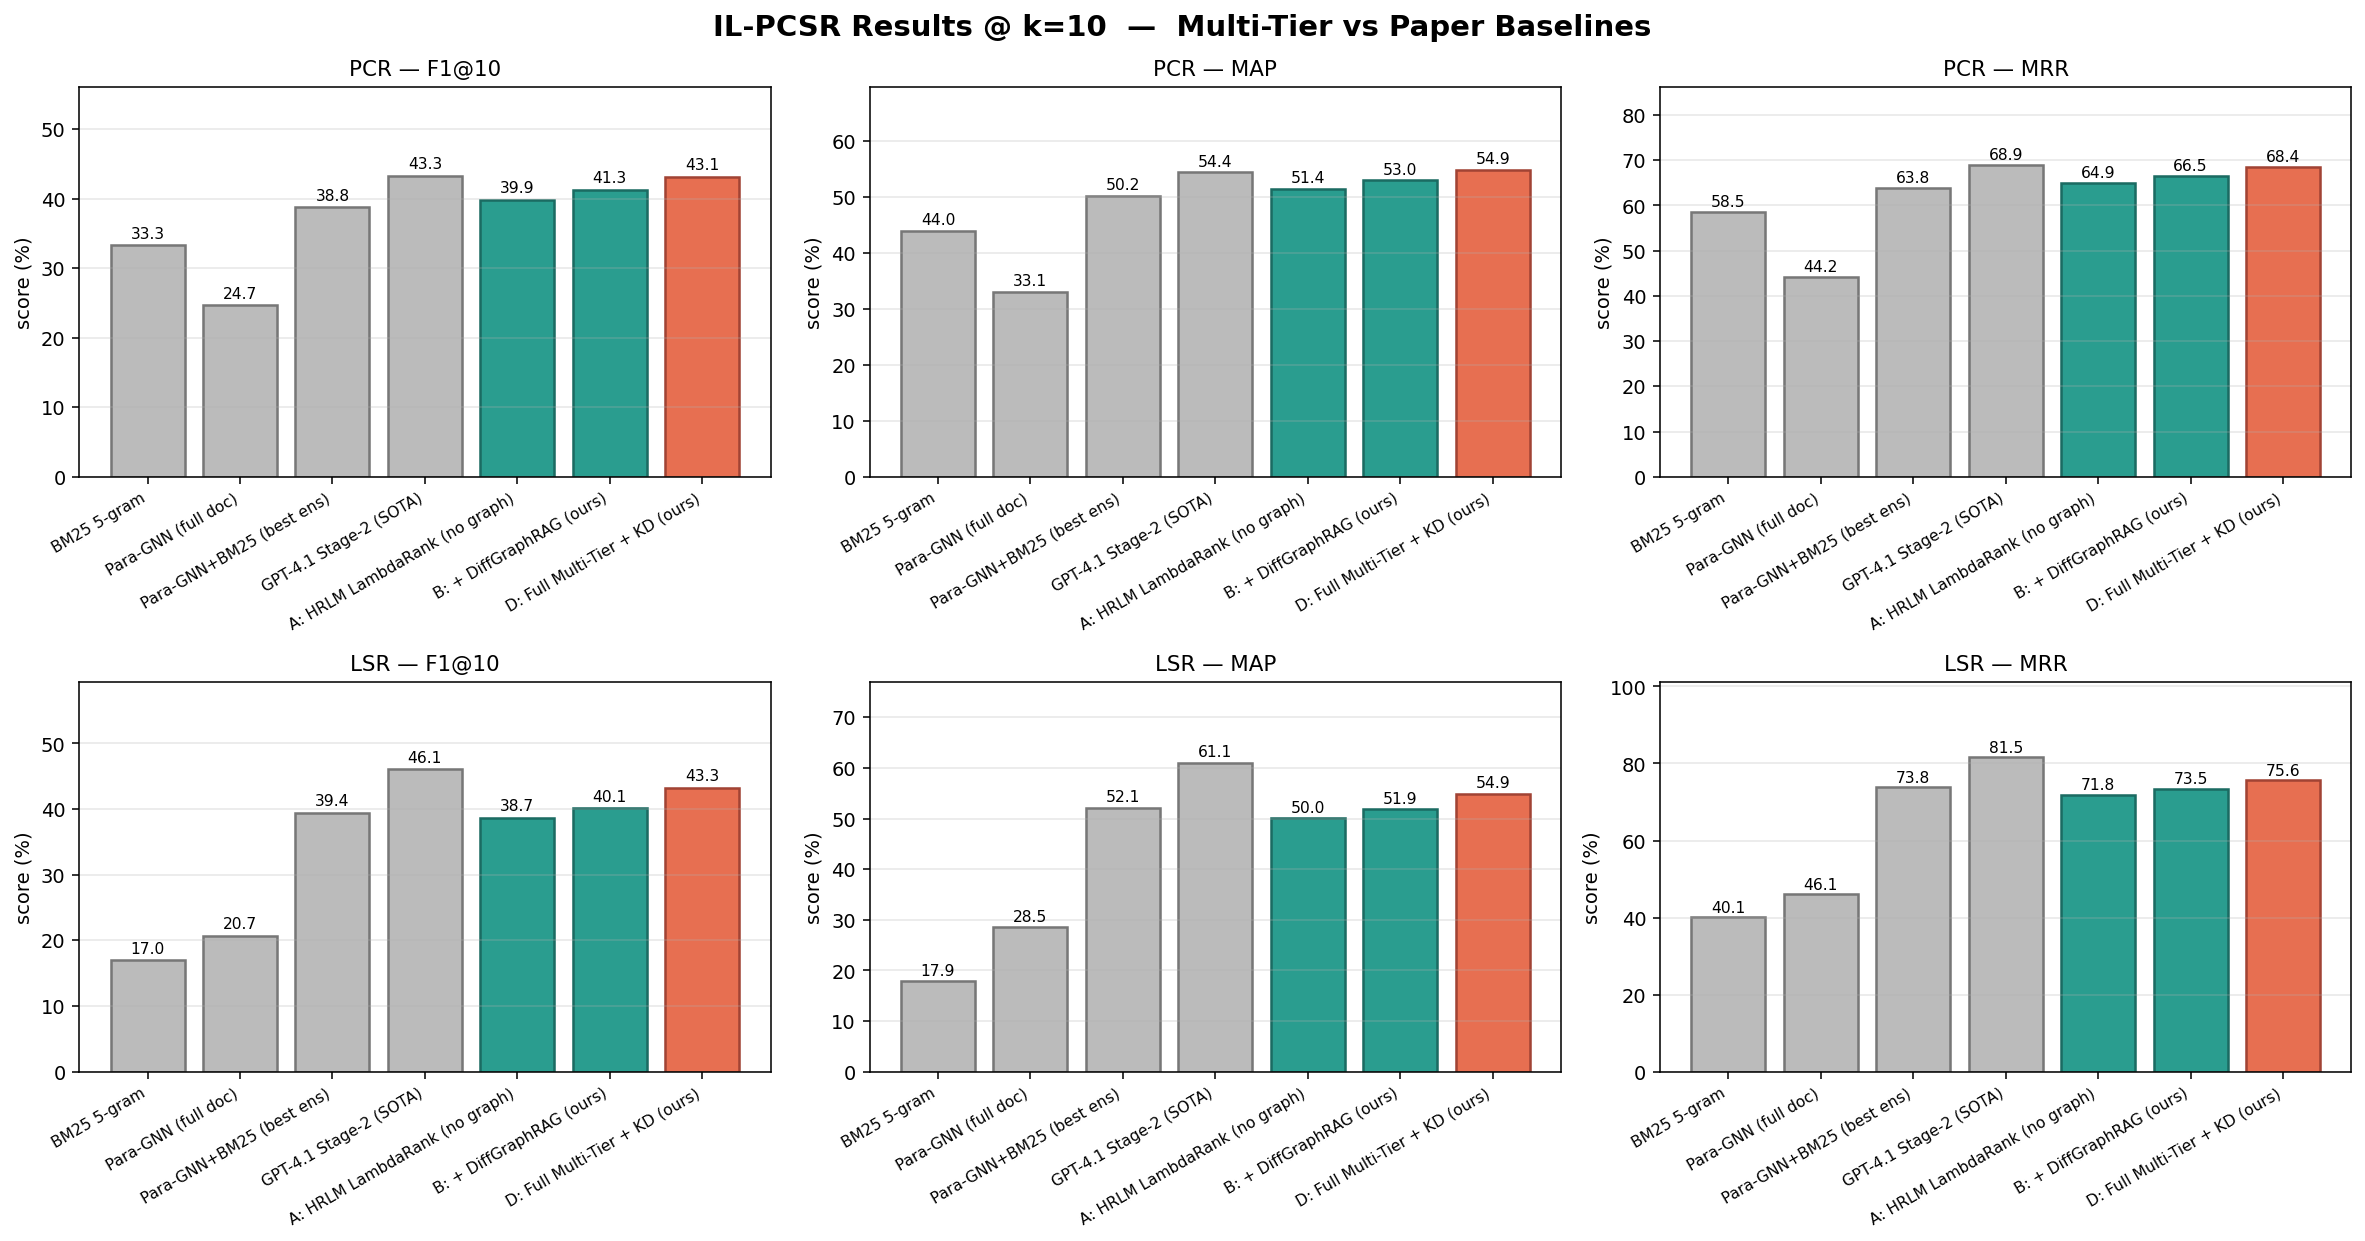

lightgbm_feature_importance_gain.png


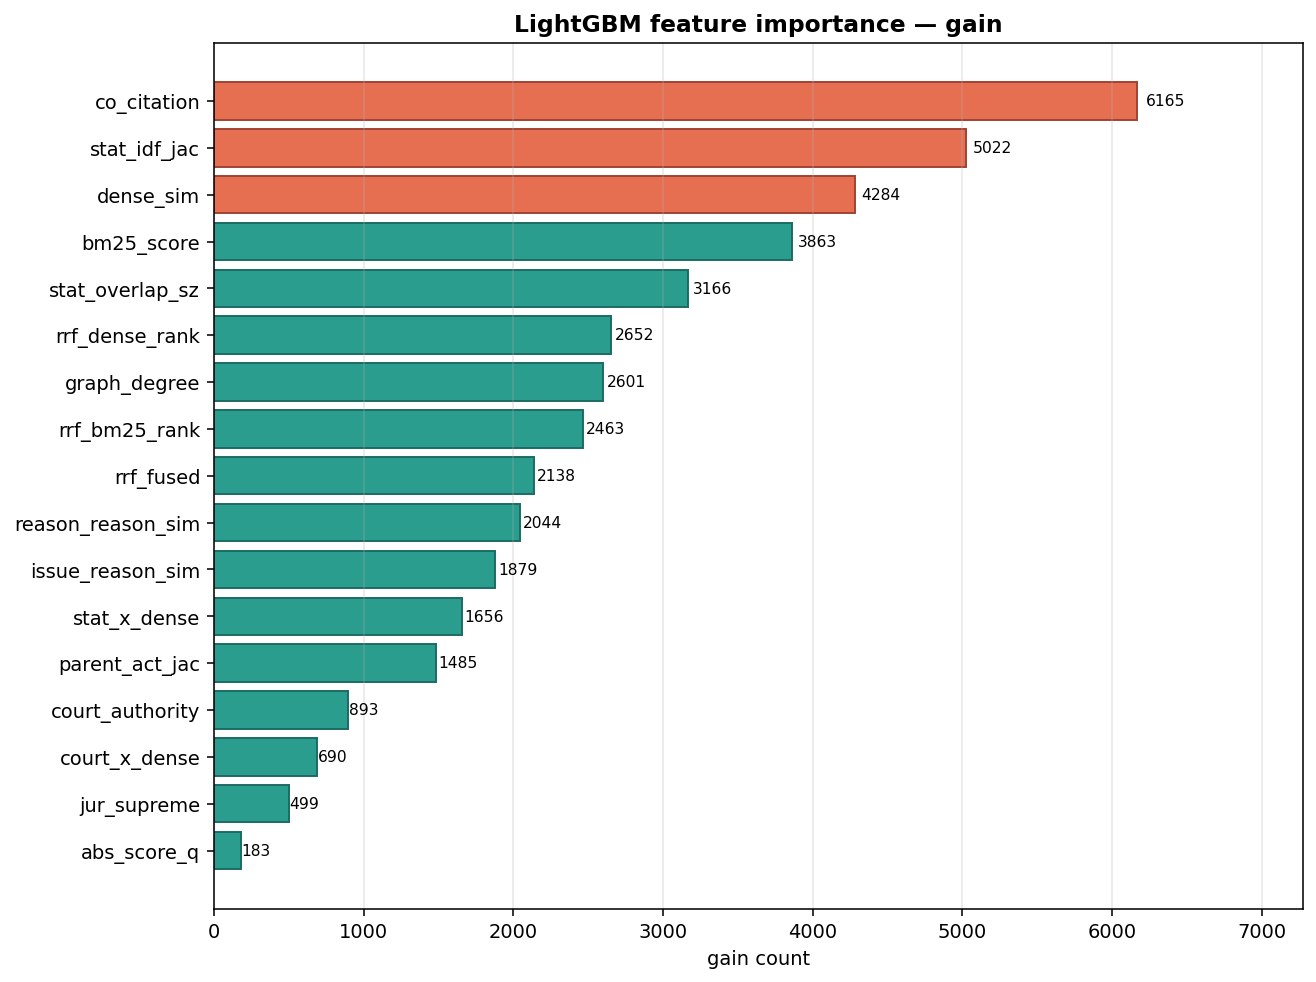

lightgbm_feature_importance_split.png


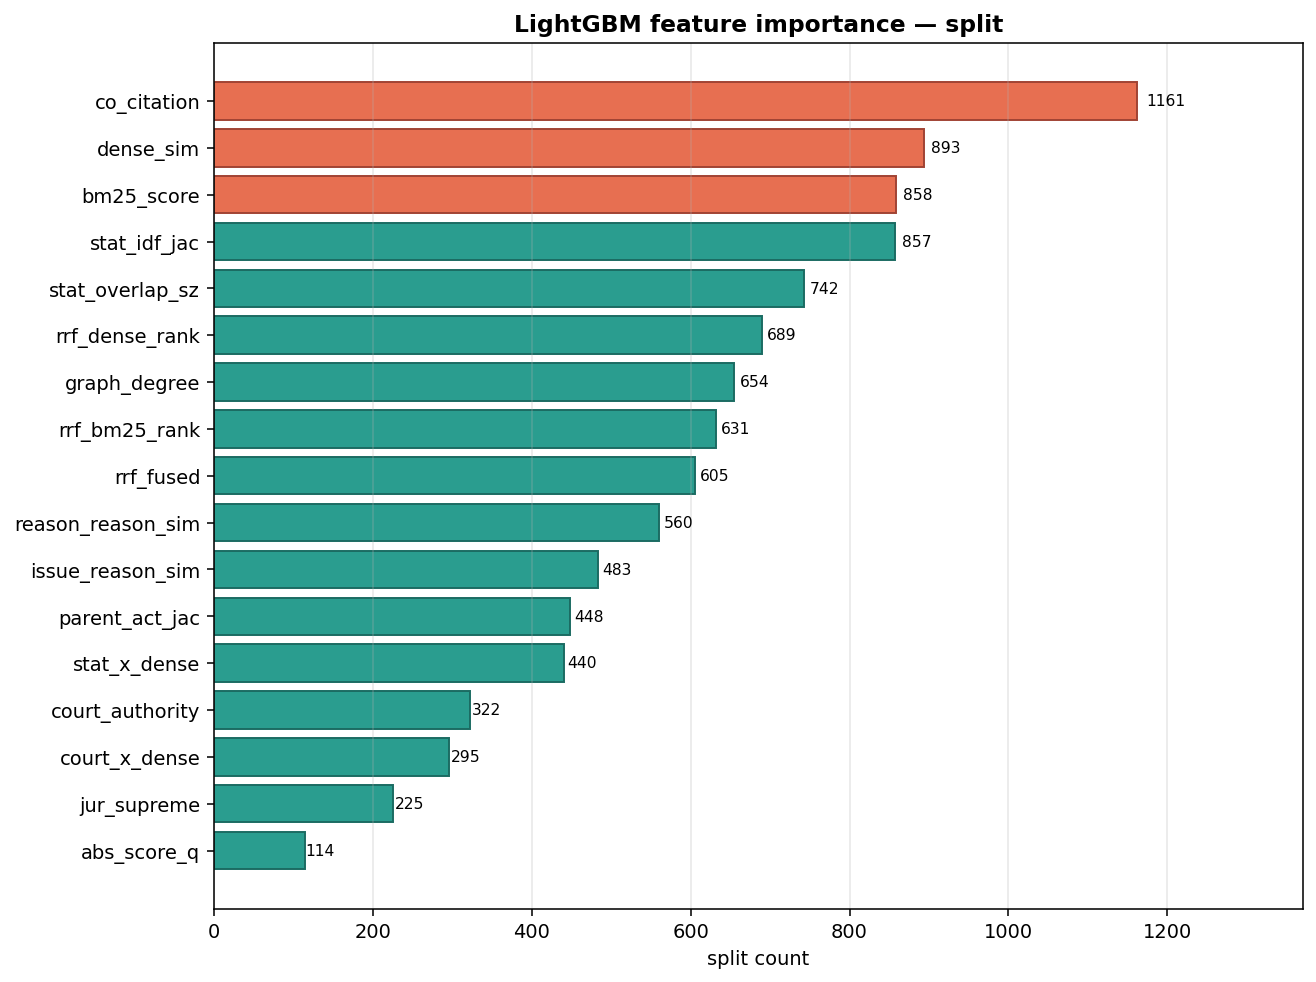

our_configs_f1.png


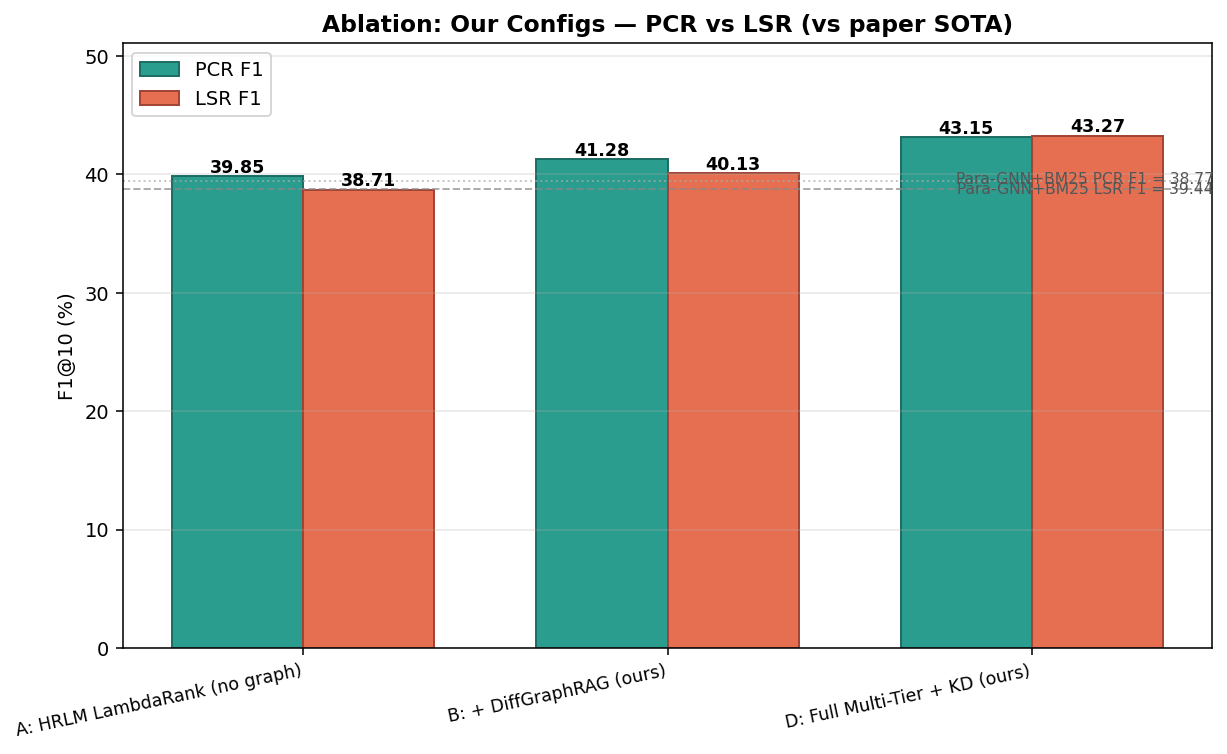

In [16]:
# ── Show outputs ────────────────────────────────────────────────────────────
import os
from IPython.display import Image, Markdown, display

ckpt = '/kaggle/working/ldrag_ckpt'
tbl = os.path.join(ckpt, 'comparison_table.md')
if os.path.exists(tbl):
    display(Markdown(open(tbl).read()))

plots_dir = os.path.join(ckpt, 'plots')
if os.path.isdir(plots_dir):
    for png in sorted(os.listdir(plots_dir)):
        if png.endswith('.png'):
            print(png)
            display(Image(filename=os.path.join(plots_dir, png)))
